In [1]:
import numpy as np
import pandas as pd
import itertools
import matplotlib
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
from matplotlib import cm
from datetime import date
import re
# from tqdm import tqdm
import time
# from pybedtools import BedTool
import random
import math
import pickle
import seaborn as sns
from scipy.stats import percentileofscore, pearsonr, rankdata, fisher_exact, describe
# from scipy.spatial.distance import jaccard, euclidean, cosine
# import functools
# import operator
import gzip
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
import sys
import os
from functools import partial
from contextlib import closing
from multiprocessing import Pool
import re
import h5py
import tabix
import upsetplot
from wordcloud import WordCloud

today = date.today()

In [2]:
def kde_wrapper(data, bw=0.1):
    fig = plt.figure()
    fig.patch.set_facecolor('white')
    
    sns.kdeplot(data, bw_adjust=bw)
    print(describe(data))
    return fig

**Breaking down scores for each ROI**

In [3]:
# DHS_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.DHSoee.npy')
# TF_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.TFoee.npy')
# epilogos_ooe = np.load('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosoee.npy')

In [93]:
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220712.cleanedgenesmapped.bed', 'r')
mapped_genes = f.readlines()
f.close()

In [94]:
DHS_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHSoee.hdf5', 'r')
DHS_ooe = DHS_ooe_hdf5['ooe_arr'][:]
DHS_ooe_hdf5.close()
TF_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFoee.hdf5', 'r')
TF_ooe = TF_ooe_hdf5['ooe_arr'][:]
TF_ooe_hdf5.close()
epilogos_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosoee.hdf5', 'r')
epilogos_ooe = epilogos_ooe_hdf5['ooe_arr'][:]
epilogos_ooe_hdf5.close()

In [95]:
#loading order of each component
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFmapped.bed', 'r')
TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHSmapped.bed', 'r')
DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

In [96]:
#descriptors for each factor
pickle_in = open('/home/ctrader/region_similarity/data/tf_motif_descriptor_dict_CT20220627.pickle', 'rb')
TFfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/region_similarity/data/DHS_descriptor_dict_CT20220627.pickle', 'rb')
DHSfact2descr = pickle.load(pickle_in)

pickle_in = open('/home/ctrader/region_similarity/data/epilogos_descriptor_dict_CT20220627.pickle', 'rb')
epilogosfact2descr = pickle.load(pickle_in)

In [97]:
DHS_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHScosine.hdf5'
TF_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFcosine.hdf5'
epilogos_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogoscosine.hdf5'
coex_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.coexpression_human_transferred_maxSTRINGsimilarity.hdf5'
# coextrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.coexpression_transferredSTRINGsimilarity.hdf5'
cooccur_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.cooccurenceSTRINGsimilarity.hdf5'
database_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.database_human_transferred_maxSTRINGsimilarity.hdf5'
exper_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.experiments_human_transferred_maxSTRINGsimilarity.hdf5'
# expertrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.experiments_transferredSTRINGsimilarity.hdf5'
fusion_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.fusionSTRINGsimilarity.hdf5'
homology_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.homologySTRINGsimilarity.hdf5'
neigh_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.neighborhood_human_transferred_maxSTRINGsimilarity.hdf5'
textmin_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.textmining_human_transferred_maxSTRINGsimilarity.hdf5'
# textmintrans_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.textmining_transferredSTRINGsimilarity.hdf5'

DHS_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHSoee.hdf5'
TF_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFoee.hdf5'
epilogos_ooe_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosoee.hdf5'

DHS_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.DHSmapped.bed'
TF_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.TFmapped.bed'
epilogos_mapped_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosmapped.bed'

regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'
gz_file_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.rownum4.bed.gz'

geneID2name_path = '/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle'

In [98]:
gene_descriptor_path = '/home/ctrader/region_similarity/data/gene_descriptors_CT20220630.npy'
gene_descriptor_arr = np.load(gene_descriptor_path)

In [99]:
DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
DHS_scaled_vals_full = DHS_hdf5['top_1000_scaled_vals'][:]
DHS_cosine_vals_full = DHS_hdf5['top_1000_cosine_vals'][:]
DHS_similar_regions_full = DHS_hdf5['top_1000_similar_regions'][:]
DHS_hdf5.close()

TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
TF_scaled_vals_full = TF_hdf5['top_1000_scaled_vals'][:]
TF_cosine_vals_full = TF_hdf5['top_1000_cosine_vals'][:]
TF_similar_regions_full = TF_hdf5['top_1000_similar_regions'][:]
TF_hdf5.close()

epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
epilogos_scaled_vals_full = epilogos_hdf5['top_1000_scaled_vals'][:]
epilogos_cosine_vals_full = epilogos_hdf5['top_1000_cosine_vals'][:]
epilogos_similar_regions_full = epilogos_hdf5['top_1000_similar_regions'][:]
epilogos_hdf5.close()

In [100]:
# def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions):
#     #max ind for combined score array
#     max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
#     #DHS scores
#     DHS_arr = np.zeros(max_ind + 1)
#     DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#     #epilogos scores
#     epilogos_arr = np.zeros(max_ind + 1)
#     epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#     #TF motif scores
#     TF_arr = np.zeros(max_ind + 1)
#     TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

#     #scoring all metrics
#     score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr))
    
#     ##labeling most contributing metrics for each region
#     contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr)), axis=0)#

#     return score_arr, contributing_cosine_arr

# def region_return(score_arr, contributing_cosine_arr, roi, regions_path):
#     #top 100 region inds and scores
#     rec_inds = np.argsort(-score_arr)[:100]
#     top_region_inds = np.append(roi, rec_inds)
#     top_region_scores = np.append(1, score_arr[rec_inds])
    
#     #most contributing metrics to the top 100 scoring regions
#     top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
#     top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
    
#     #combining scores and contributions
#     score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str), 
#                                                       np.array([' - ']*len(top_region_scores))), 
#                                           top_region_contributions)
    
#     #new 6/17/22 - adding top comp to roiurls
#     DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
#     TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
#     epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
#     epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
#     metric_top_comps = ['']
#     for ind in range(1, len(top_region_contributions)):
#         metric = top_region_contributions[ind]
#         if metric=='DHS':
#             DHS_ind_rank = rankdata(-DHS_ooe[top_region_inds[ind]])
#             top_comp = np.argsort((DHS_roi_rank+DHS_ind_rank)/2)[0]
#             metric_top_comps.append(' (' + DHS_component_order[top_comp] + ')')
#         if metric=='TF':
#             TF_ind_rank = rankdata(-TF_ooe[top_region_inds[ind]])
#             top_comp = np.argsort((TF_roi_rank+TF_ind_rank)/2)[0]
#             metric_top_comps.append(' (' + TF_component_order[top_comp] + ')')
#         if metric=='epilogos':
#             epilogos_ind_mean_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][:18])
#             epilogos_ind_max_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][18:])
#             top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_ind_mean_rank)/2)[0]
#             top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_ind_max_rank)/2)[0]
#             metric_top_comps.append(' (' + epilogos_component_order[top_mean_comp] + '/' + 
#                                     epilogos_component_order[top_max_comp] + ')')
#     metric_top_comps = np.array(metric_top_comps)
#     score_contribution_comb = np.char.add(score_contribution_comb, metric_top_comps)
    
#     #find genomic locations
#     f = open(regions_path, 'r')
#     regions = f.readlines()
#     top_regions = []
#     for ind in top_region_inds:
#         top_regions.append(regions[ind].strip().split())
#     f.close()
#     top_regions = np.array(top_regions)
#     top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))#

#     link_path, bed_path_name = roi_url(roi, top_regions)
#     print(link_path, flush=True)

#     return bed_path_name, top_region_inds

# def roi_url(roi, top_regions):
#     today = date.today()
#     roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_25kb_notebook_CT' + today.strftime("%Y%m%d") + '.bed'
#     bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
#     np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
#     link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
#     return link_path, bed_path_name

In [101]:
def breakdown_score(ind):
    DHS_ooe_1v2 = DHS_ooe[top_region_inds[[0, ind]]]
    TF_ooe_1v2 = TF_ooe[top_region_inds[[0, ind]]]
    epilogos_ooe_1v2 = epilogos_ooe[top_region_inds[[0, ind]]]

    #cosine similarity
    print('ROI =', roi)
    print('#%s in ROIurl' %(ind+1))
    print()
    print('DHS Cosine Similarity =', np.round(cosine_similarity(DHS_ooe_1v2[0].reshape(1, -1), DHS_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('TF Cosine Similarity =', np.round(cosine_similarity(TF_ooe_1v2[0].reshape(1, -1), TF_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print('Epilogos Cosine Similarity =', np.round(cosine_similarity(epilogos_ooe_1v2[0].reshape(1, -1), epilogos_ooe_1v2[1].reshape(1, -1))[0, 0], 4))
    print()
    print('1000th DHS Cosine Similarity for ROI =', np.round(DHS_cosine_vals_full[roi, -1], 4))
    print('1000th TF Cosine Similarity for ROI =', np.round(TF_cosine_vals_full[roi, -1], 4))
    print('1000th Epilogos Cosine Similarity for ROI =', np.round(epilogos_cosine_vals_full[roi, -1], 4))
    print()
    print('DHS Scaled Score =', np.round(DHS_arr[top_region_inds[ind]], 4))
    print('TF Scaled Score =', np.round(TF_arr[top_region_inds[ind]], 4))
    print('Epilogos Scaled Score =', np.round(epilogos_arr[top_region_inds[ind]], 4))
    print()
    print('Total Score =', 
          np.round(1 - ((1-DHS_arr[top_region_inds[ind]])*(1-TF_arr[top_region_inds[ind]])*(1-epilogos_arr[top_region_inds[ind]])), 4))
    print()

    #scatter plot
    fig = plt.figure(figsize=(8,8))
    fig.patch.set_facecolor('white')

    size=30

    plt.scatter(DHS_ooe_1v2[0], DHS_ooe_1v2[1], c='#1f77b4', s=size)
    plt.scatter(TF_ooe_1v2[0], TF_ooe_1v2[1], c='#ff7f0e', s=size)
    plt.scatter(epilogos_ooe_1v2[0, :18], epilogos_ooe_1v2[1, :18], c='#2ca02c', s=size)
    plt.scatter(epilogos_ooe_1v2[0, 18:], epilogos_ooe_1v2[1, 18:], marker='x', c='#2ca02c', s=size)


    plt.xlim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])
    plt.ylim([np.min([np.min(DHS_ooe_1v2), np.min(TF_ooe_1v2), np.min(epilogos_ooe_1v2)])-0.5, 
              np.max([np.max(DHS_ooe_1v2), np.max(TF_ooe_1v2), np.max(epilogos_ooe_1v2)])+0.5])

    plt.legend(['DHS Counts', 'TF Motif Counts', 'Epilogos Mean', 'Epilogos Max'])

    plt.xlabel('ROI OOE Values')
    plt.ylabel('Similar Region OOE Values')
    title='Comparing OOE Values Between ROI (%s) and Rank %s Similar Region (%s)' %(roi, ind, top_region_inds[ind])
    plt.title(title)
    print(title)
    plt.show()

In [102]:
descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.genedescriptorooe.hdf5'

descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
term_full_counts = descriptor_hdf5['term_roi_counts'][:]
descriptor_hdf5.close()

In [103]:
pickle_in = open('/home/ctrader/region_similarity/data/gene_proteinID2genename_dict_CT20220712.pickle', 'rb')
geneID2name = pickle.load(pickle_in)

In [104]:
# def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals,
#                    epilogos_score_similar_regions, coex_scaled_vals, coex_similar_regions, coextrans_scaled_vals, coextrans_similar_regions,
#                    cooccur_scaled_vals, cooccur_similar_regions, database_scaled_vals, database_similar_regions, exper_scaled_vals, exper_similar_regions,
#                    expertrans_scaled_vals, expertrans_similar_regions, fusion_scaled_vals, fusion_similar_regions, homology_scaled_vals, homology_similar_regions,
#                    neightrans_scaled_vals, neightrans_similar_regions, textmin_scaled_vals, textmin_similar_regions, textmintrans_scaled_vals,
#                    textmintrans_similar_regions):
#     #max ind for combined score array
#     max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions, coex_similar_regions, coextrans_similar_regions,
#                      cooccur_similar_regions, database_similar_regions, exper_similar_regions, expertrans_similar_regions, fusion_similar_regions, homology_similar_regions,
#                      neightrans_similar_regions, textmin_similar_regions, textmintrans_similar_regions])

#     #DHS scores
#     DHS_arr = np.zeros(max_ind + 1)
#     DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#     #epilogos scores
#     epilogos_arr = np.zeros(max_ind + 1)
#     epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#     #TF motif scores
#     TF_arr = np.zeros(max_ind + 1)
#     TF_arr[TF_count_similar_regions] = TF_count_scaled_vals
#     #coexpression scores
#     coex_arr = np.zeros(max_ind + 1)
#     coex_arr[coex_similar_regions] = coex_scaled_vals
#     #coexpression transferred scores
#     coextrans_arr = np.zeros(max_ind + 1)
#     coextrans_arr[coextrans_similar_regions] = coextrans_scaled_vals
#     #cooccurrence scores
#     cooccur_arr = np.zeros(max_ind + 1)
#     cooccur_arr[cooccur_similar_regions] = cooccur_scaled_vals
#     #database scores
#     database_arr = np.zeros(max_ind + 1)
#     database_arr[database_similar_regions] = database_scaled_vals
#     #experiment scores
#     exper_arr = np.zeros(max_ind + 1)
#     exper_arr[exper_similar_regions] = exper_scaled_vals
#     #experiment transferred scores
#     expertrans_arr = np.zeros(max_ind + 1)
#     expertrans_arr[expertrans_similar_regions] = expertrans_scaled_vals
#     #fusion scores
#     fusion_arr = np.zeros(max_ind + 1)
#     fusion_arr[fusion_similar_regions] = fusion_scaled_vals
#     #homology scores
#     homology_arr = np.zeros(max_ind + 1)
#     homology_arr[homology_similar_regions] = homology_scaled_vals
#     #neighborhood transferred scores
#     neightrans_arr = np.zeros(max_ind + 1)
#     neightrans_arr[neightrans_similar_regions] = neightrans_scaled_vals
#     #text mining scores
#     textmin_arr = np.zeros(max_ind + 1)
#     textmin_arr[textmin_similar_regions] = textmin_scaled_vals
#     #text mining transferred scores
#     textmintrans_arr = np.zeros(max_ind + 1)
#     textmintrans_arr[textmintrans_similar_regions] = textmintrans_scaled_vals

#     #scoring all metrics
#     score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr) * (1 - coex_arr) * (1 - coextrans_arr) * (1 - cooccur_arr) * (1 - database_arr) * (1 - exper_arr) *
#                      (1 - expertrans_arr) * (1 - fusion_arr) * (1 - homology_arr) * (1 - neightrans_arr) * (1 - textmin_arr) * (1 - textmintrans_arr))

#     #labeling most contributing metrics for each region
#     contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, coextrans_arr, cooccur_arr, database_arr, exper_arr, expertrans_arr,
#                                                    fusion_arr, homology_arr, neightrans_arr, textmin_arr, textmintrans_arr)), axis=0)

#     ###test can delete below
#     test = np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, coextrans_arr, cooccur_arr, database_arr, exper_arr, expertrans_arr,
#                       fusion_arr, homology_arr, neightrans_arr, textmin_arr, textmintrans_arr))
#     rec_inds = np.argsort(-score_arr)[:100]
#     ###end test
#     return score_arr, contributing_cosine_arr

# def region_return(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
#                   epilogos_mapped_path):
#     #top 100 region inds and scores
#     rec_inds = np.argsort(-score_arr)[:100]
#     top_region_inds = np.append(roi, rec_inds)
#     top_region_scores = np.append(1, score_arr[rec_inds])

#     #most contributing metrics to the top 100 scoring regions
#     top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
#     top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='3', 'Coexpression', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='4', 'Coexpression (T)', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='5', 'Cooccurrence', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='6', 'Database', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='7', 'Experiment', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='8', 'Experiment (T)', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='9', 'Fusion', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='10', 'Homology', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='11', 'Neighborhood (T)', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='12', 'Textmining', top_region_contributions)
#     top_region_contributions = np.where(top_region_contributions=='13', 'Textmining (T)', top_region_contributions)

#         #combining scores and contributions
#     score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str),
#                                                       np.array([' - ']*len(top_region_scores))),
#                                           top_region_contributions)


#     #adding top comp to roiurls
#     #component order
#     f = open(DHS_mapped_path, 'r')
#     DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
#     f.close()
#     f = open(TF_mapped_path, 'r')
#     TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
#     f.close()
#     f = open(epilogos_mapped_path, 'r')
#     epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
#     f.close()
#     #ooe arrays
#     DHS_ooe_hdf5 = h5py.File(DHS_ooe_path, 'r')
#     DHS_ooe = DHS_ooe_hdf5['ooe_arr']
#     TF_ooe_hdf5 = h5py.File(TF_ooe_path, 'r')
#     TF_ooe = TF_ooe_hdf5['ooe_arr']
#     epilogos_ooe_hdf5 = h5py.File(epilogos_ooe_path, 'r')
#     epilogos_ooe = epilogos_ooe_hdf5['ooe_arr']
#     #finding ooe of roi
#     DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
#     TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
#     epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
#     epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
#     #ooe of top metric for each region and finding top factor for roi and each region
#     metric_top_comps = ['']
#     for ind in range(1, len(top_region_contributions)):
#         metric = top_region_contributions[ind]
#         if metric=='DHS':
#             DHS_ind_rank = rankdata(-DHS_ooe[top_region_inds[ind]])
#             top_comp = np.argsort((DHS_roi_rank+DHS_ind_rank)/2)[0]
#             metric_top_comps.append(' (' + DHS_component_order[top_comp] + ')')
#         elif metric=='TF':
#             TF_ind_rank = rankdata(-TF_ooe[top_region_inds[ind]])
#             top_comp = np.argsort((TF_roi_rank+TF_ind_rank)/2)[0]
#             metric_top_comps.append(' (' + TF_component_order[top_comp] + ')')
#         elif metric=='epilogos':
#             epilogos_ind_mean_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][:18])
#             epilogos_ind_max_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][18:])
#             top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_ind_mean_rank)/2)[0]
#             top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_ind_max_rank)/2)[0]
#             metric_top_comps.append(' (' + epilogos_component_order[top_mean_comp] + '/' +
#                                     epilogos_component_order[top_max_comp] + ')')
#         else:
#             metric_top_comps.append(' ')

#     DHS_ooe_hdf5.close()
#     TF_ooe_hdf5.close()
#     epilogos_ooe_hdf5.close()
#     #add to roiurl data
#     metric_top_comps = np.array(metric_top_comps)
#     score_contribution_comb = np.char.add(score_contribution_comb, metric_top_comps)


#     #find genomic locations
#     f = open(regions_path, 'r')
#     regions = f.readlines()
#     top_regions = []
#     for ind in top_region_inds:
#         top_regions.append(regions[ind].strip().split())
#     f.close()
#     top_regions = np.array(top_regions)
#     top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))

#     link_path, bed_path_name = roi_url(roi, top_regions)
#     print(link_path, flush=True)

#     return bed_path_name, top_region_inds

# def roi_url(roi, top_regions):
#     today = date.today()
#     roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
#     bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
#     np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
#     link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
#     return link_path, bed_path_name

# def load_hdf5_files(hdf5_path, roi):
#     #take in a file path and load scaled scores and similar regions
#     hdf5_file = h5py.File(hdf5_path, 'r')
#     scaled_vals = hdf5_file['top_1000_scaled_vals'][roi]
#     similar_regions = hdf5_file['top_1000_similar_regions'][roi]
#     hdf5_file.close()
#     return scaled_vals, similar_regions

# def load_hdf5_files_find_distribution(hdf5_path, roi):
#     #take in a file path and load scaled scores and similar regions
#     hdf5_file = h5py.File(hdf5_path, 'r')
#     scaled_vals = hdf5_file['top_1000_scaled_vals'][:]
# #     similar_regions = hdf5_file['top_1000_similar_regions'][:]
#     string_vals = hdf5_file['top_1000_STRING_vals'][:]
#     hdf5_file.close()
#     print(hdf5_path)
#     f = kde_wrapper(string_vals[string_vals!=0], bw=0.5)
#     plt.title('Non-zero STRING Scores')
#     plt.show(block=False)
#     f = kde_wrapper(scaled_vals[scaled_vals!=0])
#     plt.title('Current Scaled Scores')
#     plt.show(block=False)
#     newly_scaled = scale_data(string_vals, max_poss=1000)
#     f = kde_wrapper(newly_scaled)
#     plt.title('Proposed Scaled Scores')
#     plt.show(block=False)
#     return 

In [105]:
def combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals,
                   epilogos_score_similar_regions, coex_scaled_vals, coex_similar_regions, cooccur_scaled_vals, cooccur_similar_regions,
                   database_scaled_vals, database_similar_regions, exper_scaled_vals, exper_similar_regions,fusion_scaled_vals, fusion_similar_regions,
                   homology_scaled_vals, homology_similar_regions, neigh_scaled_vals, neigh_similar_regions, textmin_scaled_vals, textmin_similar_regions):
    #max ind for combined score array
    max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions, coex_similar_regions,
                     cooccur_similar_regions, database_similar_regions, exper_similar_regions, fusion_similar_regions, homology_similar_regions,
                     neigh_similar_regions, textmin_similar_regions])

    #DHS scores
    DHS_arr = np.zeros(max_ind + 1)
    DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
    #epilogos scores
    epilogos_arr = np.zeros(max_ind + 1)
    epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
    #TF motif scores
    TF_arr = np.zeros(max_ind + 1)
    TF_arr[TF_count_similar_regions] = TF_count_scaled_vals
    #coexpression scores
    coex_arr = np.zeros(max_ind + 1)
    coex_arr[coex_similar_regions] = coex_scaled_vals
    #cooccurrence scores
    cooccur_arr = np.zeros(max_ind + 1)
    cooccur_arr[cooccur_similar_regions] = cooccur_scaled_vals
    #database scores
    database_arr = np.zeros(max_ind + 1)
    database_arr[database_similar_regions] = database_scaled_vals
    #experiment scores
    exper_arr = np.zeros(max_ind + 1)
    exper_arr[exper_similar_regions] = exper_scaled_vals
    #fusion scores
    fusion_arr = np.zeros(max_ind + 1)
    fusion_arr[fusion_similar_regions] = fusion_scaled_vals
    #homology scores
    homology_arr = np.zeros(max_ind + 1)
    homology_arr[homology_similar_regions] = homology_scaled_vals
    #neighborhood scores
    neigh_arr = np.zeros(max_ind + 1)
    neigh_arr[neigh_similar_regions] = neigh_scaled_vals
    #text mining scores
    textmin_arr = np.zeros(max_ind + 1)
    textmin_arr[textmin_similar_regions] = textmin_scaled_vals

    #scoring all metrics
    score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr) * (1 - coex_arr) * (1 - cooccur_arr) * (1 - database_arr) * (1 - exper_arr) *
                     (1 - fusion_arr) * (1 - homology_arr) * (1 - neigh_arr) * (1 - textmin_arr))

    #labeling most contributing metrics for each region
    contributing_cosine_arr = np.argmax(np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, database_arr, exper_arr, fusion_arr,
                                                   homology_arr, neigh_arr, textmin_arr)), axis=0)

    return score_arr, contributing_cosine_arr, max_ind

def region_return(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
                  epilogos_mapped_path, coex_genes, cooccur_genes, database_genes, exper_genes, fusion_genes, homology_genes, neigh_genes,
                  textmin_genes, geneID2name_path):
    #load geneID2name dictionary
    pickle_in = open(geneID2name_path, 'rb')
    geneID2name = pickle.load(pickle_in)

    #top 100 region inds and scores
    rec_inds = np.argsort(-score_arr)[:100]
    top_region_inds = np.append(roi, rec_inds)
    top_region_scores = np.append(1, score_arr[rec_inds])

    #most contributing metrics to the top 100 scoring regions
    top_region_contributions = np.append('ROI', contributing_cosine_arr[rec_inds])
    top_region_contributions = np.where(top_region_contributions=='0', 'DHS', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='1', 'TF', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='2', 'epilogos', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='3', 'Coexpression', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='4', 'Cooccurrence', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='5', 'Database', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='6', 'Experiment', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='7', 'Fusion', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='8', 'Homology', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='9', 'Neighborhood', top_region_contributions)
    top_region_contributions = np.where(top_region_contributions=='10', 'Textmining', top_region_contributions)



    #combining scores and contributions
    score_contribution_comb = np.char.add(np.char.add(np.round(top_region_scores, 4).astype(str),
                                                      np.array([' - ']*len(top_region_scores))),
                                          top_region_contributions)


    #adding top comp to roiurls
    #component order
    f = open(DHS_mapped_path, 'r')
    DHS_component_order = np.array(f.readline().strip().split('\t'))[3:]
    f.close()
    f = open(TF_mapped_path, 'r')
    TF_component_order = np.array(f.readline().strip().split('\t'))[3:]
    f.close()
    f = open(epilogos_mapped_path, 'r')
    epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
    f.close()
    #ooe arrays
    DHS_ooe_hdf5 = h5py.File(DHS_ooe_path, 'r')
    DHS_ooe = DHS_ooe_hdf5['ooe_arr']
    TF_ooe_hdf5 = h5py.File(TF_ooe_path, 'r')
    TF_ooe = TF_ooe_hdf5['ooe_arr']
    epilogos_ooe_hdf5 = h5py.File(epilogos_ooe_path, 'r')
    epilogos_ooe = epilogos_ooe_hdf5['ooe_arr']
    #finding ooe of roi
    DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
    TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
    epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
    epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
    #ooe of top metric for each region and finding top factor for roi and each region
    metric_top_comps = ['']
    for ind in range(1, len(top_region_contributions)):
        metric = top_region_contributions[ind]
        if metric=='DHS':
            DHS_ind_rank = rankdata(-DHS_ooe[top_region_inds[ind]])
            top_comp = np.argsort((DHS_roi_rank+DHS_ind_rank)/2)[0]
            metric_top_comps.append(' (' + DHS_component_order[top_comp] + ')')
        elif metric=='TF':
            TF_ind_rank = rankdata(-TF_ooe[top_region_inds[ind]])
            top_comp = np.argsort((TF_roi_rank+TF_ind_rank)/2)[0]
            metric_top_comps.append(' (' + TF_component_order[top_comp] + ')')
        elif metric=='epilogos':
            epilogos_ind_mean_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][:18])
            epilogos_ind_max_rank = rankdata(-epilogos_ooe[top_region_inds[ind]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_ind_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_ind_max_rank)/2)[0]
            metric_top_comps.append(' (' + epilogos_component_order[top_mean_comp] + '/' +
                                    epilogos_component_order[top_max_comp] + ')')
        elif metric=='Coexpression':
            metric_top_comps.append(' (' + geneID2name[coex_genes[0, top_region_inds[ind]]] + '/' + geneID2name[coex_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Cooccurrence':
            metric_top_comps.append(' (' + geneID2name[cooccur_genes[0, top_region_inds[ind]]] + '/' + geneID2name[cooccur_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Database':
            metric_top_comps.append(' (' + geneID2name[database_genes[0, top_region_inds[ind]]] + '/' + geneID2name[database_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Experiment':
            metric_top_comps.append(' (' + geneID2name[exper_genes[0, top_region_inds[ind]]] + '/' + geneID2name[exper_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Fusion':
            metric_top_comps.append(' (' + geneID2name[fusion_genes[0, top_region_inds[ind]]] + '/' + geneID2name[fusion_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Homology':
            metric_top_comps.append(' (' + geneID2name[homology_genes[0, top_region_inds[ind]]] + '/' + geneID2name[homology_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Neighborhood':
            metric_top_comps.append(' (' + geneID2name[neigh_genes[0, top_region_inds[ind]]] + '/' + geneID2name[neigh_genes[1, top_region_inds[ind]]] + ')')
        elif metric=='Textmining':
            metric_top_comps.append(' (' + geneID2name[textmin_genes[0, top_region_inds[ind]]] + '/' + geneID2name[textmin_genes[1, top_region_inds[ind]]] + ')')

    DHS_ooe_hdf5.close()
    TF_ooe_hdf5.close()
    epilogos_ooe_hdf5.close()
    #add to roiurl data
    metric_top_comps = np.array(metric_top_comps)
    score_contribution_comb = np.char.add(score_contribution_comb, metric_top_comps)
    
    #find genomic locations
    f = open(regions_path, 'r')
    regions = f.readlines()
    top_regions = []
    for ind in top_region_inds:
        top_regions.append(regions[ind].strip().split())
    f.close()
    top_regions = np.array(top_regions)
    top_regions = np.hstack((top_regions, score_contribution_comb.reshape((len(score_contribution_comb), 1))))

    link_path, bed_path_name = roi_url(roi, top_regions)
    print(link_path, flush=True)

    return bed_path_name, top_region_inds

def roi_url(roi, top_regions):
    today = date.today()
    roi_url_name = 'region_comparison_recommended_regions_roi_'+str(roi)+'_scale_25kb_CT' + today.strftime("%Y%m%d") + '.bed'
    bed_path_name = os.path.join('/home/ctrader/public_html/', roi_url_name)
    np.savetxt(bed_path_name, top_regions, delimiter='\t', fmt='%s')
    link_path = 'https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2F' + roi_url_name
    return link_path, bed_path_name

def load_hdf5_files(hdf5_path, roi):
    #take in a file path and load scaled scores and similar regions
    hdf5_file = h5py.File(hdf5_path, 'r')
    scaled_vals = hdf5_file['top_1000_scaled_vals'][roi]
    similar_regions = hdf5_file['top_1000_similar_regions'][roi]
    hdf5_file.close()
    return scaled_vals, similar_regions

def load_hdf5_genes(hdf5_path, roi, similar_regions, max_ind):
    #load in tracking genes
    hdf5_file = h5py.File(hdf5_path, 'r')
    ori_genes = np.char.decode(hdf5_file['top_1000_original_genes'][roi], 'utf-8')
    dest_genes = np.char.decode(hdf5_file['top_1000_destination_genes'][roi], 'utf-8')
    #establishing gene arrays
    ori_arr = np.array([None]*max_ind)
    dest_arr = np.array([None]*max_ind)
    #filling gene arrays
    ori_arr[similar_regions] = ori_genes
    dest_arr[similar_regions] = dest_genes
    return np.array([ori_arr, dest_arr])

In [106]:
# def scale_data(data, max_poss):
#     data_to_rank = data[data!=0]
#     max_obs = np.max(data_to_rank)
#     rank_data = rankdata(data_to_rank, method='average')
#     rank_data = rank_data/(len(data_to_rank))
#     rank_data = rank_data * max_obs/max_poss
    
#     original_data_shape = data.shape
#     data = data.astype(float).flatten()
#     np.put(data, np.where(data!=0)[0], rank_data)
#     data = data.reshape(original_data_shape)
#     return data
# data = np.array([[900, 0, 0], [900, 800, 10], [950, 0, 0]])
# scale_data(data, max_poss)

In [107]:
#find roi
genomic_location = 'chr20:19756800-19756801'
gz_tb = tabix.open(gz_file_path)
roi = int(list(gz_tb.querys(genomic_location))[0][3])

# # #determine roi
# roi=12345

# determine roi - best
roi=21861 #np.argsort(-average_of_scores)[6]
# roi=np.argsort(-average_of_scores)[0]


# genomic_location = 'chr12:102945600-102970600'
# gz_tb = tabix.open(gz_file_path)
# roi = int(list(gz_tb.querys(genomic_location))[0][3])

# genomic_location = 'chr20:62264763-62348156'
# gz_tb = tabix.open(gz_file_path)
# roi = int(list(gz_tb.querys(genomic_location))[0][3])

In [108]:
# print('roi = ' + str(roi), flush=True)
# t = time.time()
# ###Load rank and ind arrays
# #DHS counts
# DHS_hdf5 = h5py.File(DHS_hdf5_path, 'r')
# DHS_count_scaled_vals = DHS_hdf5['top_1000_scaled_vals'][roi]
# DHS_count_similar_regions = DHS_hdf5['top_1000_similar_regions'][roi]
# DHS_hdf5.close()

# #TF motif counts
# TF_hdf5 = h5py.File(TF_hdf5_path, 'r')
# TF_count_scaled_vals = TF_hdf5['top_1000_scaled_vals'][roi]
# TF_count_similar_regions = TF_hdf5['top_1000_similar_regions'][roi]
# TF_hdf5.close()

# #epilogos score sum and max
# epilogos_hdf5 = h5py.File(epilogos_hdf5_path, 'r')
# epilogos_score_scaled_vals = epilogos_hdf5['top_1000_scaled_vals'][roi]
# epilogos_score_similar_regions = epilogos_hdf5['top_1000_similar_regions'][roi]
# epilogos_hdf5.close()

# ###Combine scores 
# #
# score_arr, contributing_cosine_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals, epilogos_score_similar_regions)


# ###Return regions
# bed_path_name, top_region_inds = region_return(score_arr, contributing_cosine_arr, roi, regions_path)
# print(time.time()-t)

In [109]:
# #coexpression STRING scores
# load_hdf5_files_find_distribution(coex_hdf5_path, roi)
# #coexpression transferred STRING scores    
# load_hdf5_files_find_distribution(coextrans_hdf5_path, roi)
# #cooccurence STRING scores
# load_hdf5_files_find_distribution(cooccur_hdf5_path, roi)
# #database STRING scores
# load_hdf5_files_find_distribution(database_hdf5_path, roi)
# #experiments STRING scores
# load_hdf5_files_find_distribution(exper_hdf5_path, roi)
# #experiments transferred STRING scores
# load_hdf5_files_find_distribution(expertrans_hdf5_path, roi)
# #fusion STRING scores
# load_hdf5_files_find_distribution(fusion_hdf5_path, roi)
# #homology STRING scores
# load_hdf5_files_find_distribution(homology_hdf5_path, roi)
# #neighborhood transferred STRING scores
# load_hdf5_files_find_distribution(neightrans_hdf5_path, roi)
# #textmining STRING scores
# load_hdf5_files_find_distribution(textmin_hdf5_path, roi)
# #textmining transferred STRING scores
# load_hdf5_files_find_distribution(textmintrans_hdf5_path, roi)

In [110]:
# print('roi = ' + str(roi), flush=True)
# t = time.time()

# ###Load rank and ind arrays
# #DHS counts
# DHS_count_scaled_vals, DHS_count_similar_regions = load_hdf5_files(DHS_hdf5_path, roi)
# #TF motif counts
# TF_count_scaled_vals, TF_count_similar_regions = load_hdf5_files(TF_hdf5_path, roi)
# #epilogos score sum and max
# epilogos_score_scaled_vals, epilogos_score_similar_regions = load_hdf5_files(epilogos_hdf5_path, roi)
# #coexpression STRING scores
# coex_scaled_vals, coex_similar_regions = load_hdf5_files(coex_hdf5_path, roi)
# #coexpression transferred STRING scores    
# coextrans_scaled_vals, coextrans_similar_regions = load_hdf5_files(coextrans_hdf5_path, roi)
# #cooccurence STRING scores
# cooccur_scaled_vals, cooccur_similar_regions = load_hdf5_files(cooccur_hdf5_path, roi)
# #database STRING scores
# database_scaled_vals, database_similar_regions = load_hdf5_files(database_hdf5_path, roi)
# #experiments STRING scores
# exper_scaled_vals, exper_similar_regions = load_hdf5_files(exper_hdf5_path, roi)
# #experiments transferred STRING scores
# expertrans_scaled_vals, expertrans_similar_regions = load_hdf5_files(expertrans_hdf5_path, roi)
# #fusion STRING scores
# fusion_scaled_vals, fusion_similar_regions = load_hdf5_files(fusion_hdf5_path, roi)
# #homology STRING scores
# homology_scaled_vals, homology_similar_regions = load_hdf5_files(homology_hdf5_path, roi)
# #neighborhood transferred STRING scores
# neightrans_scaled_vals, neightrans_similar_regions = load_hdf5_files(neightrans_hdf5_path, roi)
# #textmining STRING scores
# textmin_scaled_vals, textmin_similar_regions = load_hdf5_files(textmin_hdf5_path, roi)
# #textmining transferred STRING scores
# textmintrans_scaled_vals, textmintrans_similar_regions = load_hdf5_files(textmintrans_hdf5_path, roi)

# ###Combine scores 
# score_arr, contributing_cosine_arr = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals,
#                                                     epilogos_score_similar_regions, coex_scaled_vals, coex_similar_regions, coextrans_scaled_vals, coextrans_similar_regions,
#                                                     cooccur_scaled_vals, cooccur_similar_regions, database_scaled_vals, database_similar_regions, exper_scaled_vals, exper_similar_regions,
#                                                     expertrans_scaled_vals, expertrans_similar_regions, fusion_scaled_vals, fusion_similar_regions, homology_scaled_vals, homology_similar_regions,
#                                                     neightrans_scaled_vals, neightrans_similar_regions, textmin_scaled_vals, textmin_similar_regions, textmintrans_scaled_vals,
#                                                     textmintrans_similar_regions)

# ###Return regions
# bed_path_name, top_region_inds = region_return(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
#                                                epilogos_mapped_path)
# print(bed_path_name)
# print(time.time()-t)

In [111]:
print('roi = ' + str(roi), flush=True)
t = time.time()

###Load rank and ind arrays
#DHS counts
DHS_count_scaled_vals, DHS_count_similar_regions = load_hdf5_files(DHS_hdf5_path, roi)
#TF motif counts
TF_count_scaled_vals, TF_count_similar_regions = load_hdf5_files(TF_hdf5_path, roi)
#epilogos score sum and max
epilogos_score_scaled_vals, epilogos_score_similar_regions = load_hdf5_files(epilogos_hdf5_path, roi)
#coexpression STRING scores
coex_scaled_vals, coex_similar_regions = load_hdf5_files(coex_hdf5_path, roi)
#cooccurence STRING scores
cooccur_scaled_vals, cooccur_similar_regions = load_hdf5_files(cooccur_hdf5_path, roi)
#database STRING scores
database_scaled_vals, database_similar_regions = load_hdf5_files(database_hdf5_path, roi)
#experiments STRING scores
exper_scaled_vals, exper_similar_regions = load_hdf5_files(exper_hdf5_path, roi)
#fusion STRING scores
fusion_scaled_vals, fusion_similar_regions = load_hdf5_files(fusion_hdf5_path, roi)
#homology STRING scores
homology_scaled_vals, homology_similar_regions = load_hdf5_files(homology_hdf5_path, roi)
#neighborhood STRING scores
neigh_scaled_vals, neigh_similar_regions = load_hdf5_files(neigh_hdf5_path, roi)
#textmining STRING scores
textmin_scaled_vals, textmin_similar_regions = load_hdf5_files(textmin_hdf5_path, roi)

###Combine scores 
score_arr, contributing_cosine_arr, max_ind = combine_scores(DHS_count_scaled_vals, DHS_count_similar_regions, TF_count_scaled_vals, TF_count_similar_regions, epilogos_score_scaled_vals,
                                                             epilogos_score_similar_regions, coex_scaled_vals, coex_similar_regions,        cooccur_scaled_vals, cooccur_similar_regions,
                                                             database_scaled_vals, database_similar_regions, exper_scaled_vals, exper_similar_regions, fusion_scaled_vals, fusion_similar_regions,
                                                             homology_scaled_vals, homology_similar_regions, neigh_scaled_vals, neigh_similar_regions, textmin_scaled_vals, textmin_similar_regions)

#load in gene names for STRING scores
coex_genes = load_hdf5_genes(coex_hdf5_path, roi, coex_similar_regions, max_ind)
cooccur_genes = load_hdf5_genes(cooccur_hdf5_path, roi, cooccur_similar_regions, max_ind)
database_genes = load_hdf5_genes(database_hdf5_path, roi, database_similar_regions, max_ind)
exper_genes = load_hdf5_genes(exper_hdf5_path, roi, exper_similar_regions, max_ind)
fusion_genes = load_hdf5_genes(fusion_hdf5_path, roi, fusion_similar_regions, max_ind)
homology_genes = load_hdf5_genes(homology_hdf5_path, roi, homology_similar_regions, max_ind)
neigh_genes = load_hdf5_genes(neigh_hdf5_path, roi, neigh_similar_regions, max_ind)
textmin_genes = load_hdf5_genes(textmin_hdf5_path, roi, textmin_similar_regions, max_ind)

###Return regions
bed_path_name, top_region_inds = region_return(score_arr, contributing_cosine_arr, roi, regions_path, DHS_ooe_path, TF_ooe_path, epilogos_ooe_path, DHS_mapped_path, TF_mapped_path,
                                               epilogos_mapped_path, coex_genes, cooccur_genes, database_genes, exper_genes, fusion_genes, homology_genes, neigh_genes,
                                               textmin_genes, geneID2name_path)
print(bed_path_name)
print(time.time()-t)

roi = 21861
https://epilogos.altius.org:3001/?application=viewer&sampleSet=vC&mode=single&genome=hg38&model=18&complexity=KL&group=all&chrLeft=chr1&chrRight=chr1&start=8000&stop=35000&roiURL=https%3A%2F%2Fencode%3Acollabor8%40resources.altius.org%2F~ctrader%2Fregion_comparison_recommended_regions_roi_21861_scale_25kb_CT20220714.bed
/home/ctrader/public_html/region_comparison_recommended_regions_roi_21861_scale_25kb_CT20220714.bed
4.362289190292358


In [112]:
# max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions])
# #DHS scores
# DHS_arr = np.zeros(max_ind + 1)
# DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
# #epilogos scores
# epilogos_arr = np.zeros(max_ind + 1)
# epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
# #TF motif scores
# TF_arr = np.zeros(max_ind + 1)
# TF_arr[TF_count_similar_regions] = TF_count_scaled_vals

In [113]:
# #max ind for combined score array
# max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions, coex_similar_regions, coextrans_similar_regions,
#                  cooccur_similar_regions, database_similar_regions, exper_similar_regions, expertrans_similar_regions, fusion_similar_regions, homology_similar_regions,
#                  neightrans_similar_regions, textmin_similar_regions, textmintrans_similar_regions])

# #DHS scores
# DHS_arr = np.zeros(max_ind + 1)
# DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
# #epilogos scores
# epilogos_arr = np.zeros(max_ind + 1)
# epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
# #TF motif scores
# TF_arr = np.zeros(max_ind + 1)
# TF_arr[TF_count_similar_regions] = TF_count_scaled_vals
# #coexpression scores
# coex_arr = np.zeros(max_ind + 1)
# coex_arr[coex_similar_regions] = coex_scaled_vals
# #coexpression transferred scores
# coextrans_arr = np.zeros(max_ind + 1)
# coextrans_arr[coextrans_similar_regions] = coextrans_scaled_vals
# #cooccurrence scores
# cooccur_arr = np.zeros(max_ind + 1)
# cooccur_arr[cooccur_similar_regions] = cooccur_scaled_vals
# #database scores
# database_arr = np.zeros(max_ind + 1)
# database_arr[database_similar_regions] = database_scaled_vals
# #experiment scores
# exper_arr = np.zeros(max_ind + 1)
# exper_arr[exper_similar_regions] = exper_scaled_vals
# #experiment transferred scores
# expertrans_arr = np.zeros(max_ind + 1)
# expertrans_arr[expertrans_similar_regions] = expertrans_scaled_vals
# #fusion scores
# fusion_arr = np.zeros(max_ind + 1)
# fusion_arr[fusion_similar_regions] = fusion_scaled_vals
# #homology scores
# homology_arr = np.zeros(max_ind + 1)
# homology_arr[homology_similar_regions] = homology_scaled_vals
# #neighborhood transferred scores
# neightrans_arr = np.zeros(max_ind + 1)
# neightrans_arr[neightrans_similar_regions] = neightrans_scaled_vals
# #text mining scores
# textmin_arr = np.zeros(max_ind + 1)
# textmin_arr[textmin_similar_regions] = textmin_scaled_vals
# #text mining transferred scores
# textmintrans_arr = np.zeros(max_ind + 1)
# textmintrans_arr[textmintrans_similar_regions] = textmintrans_scaled_vals

# #scoring all metrics
# score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr) * (1 - coex_arr) * (1 - coextrans_arr) * (1 - cooccur_arr) * (1 - database_arr) * (1 - exper_arr) *
#                  (1 - expertrans_arr) * (1 - fusion_arr) * (1 - homology_arr) * (1 - neightrans_arr) * (1 - textmin_arr) * (1 - textmintrans_arr))

In [114]:
#max ind for combined score array
max_ind = np.max([DHS_count_similar_regions, TF_count_similar_regions, epilogos_score_similar_regions, coex_similar_regions,
                 cooccur_similar_regions, database_similar_regions, exper_similar_regions, fusion_similar_regions, homology_similar_regions,
                 neigh_similar_regions, textmin_similar_regions])

#DHS scores
DHS_arr = np.zeros(max_ind + 1)
DHS_arr[DHS_count_similar_regions] = DHS_count_scaled_vals
#epilogos scores
epilogos_arr = np.zeros(max_ind + 1)
epilogos_arr[epilogos_score_similar_regions] = epilogos_score_scaled_vals
#TF motif scores
TF_arr = np.zeros(max_ind + 1)
TF_arr[TF_count_similar_regions] = TF_count_scaled_vals
#coexpression scores
coex_arr = np.zeros(max_ind + 1)
coex_arr[coex_similar_regions] = coex_scaled_vals
#cooccurrence scores
cooccur_arr = np.zeros(max_ind + 1)
cooccur_arr[cooccur_similar_regions] = cooccur_scaled_vals
#database scores
database_arr = np.zeros(max_ind + 1)
database_arr[database_similar_regions] = database_scaled_vals
#experiment scores
exper_arr = np.zeros(max_ind + 1)
exper_arr[exper_similar_regions] = exper_scaled_vals
#fusion scores
fusion_arr = np.zeros(max_ind + 1)
fusion_arr[fusion_similar_regions] = fusion_scaled_vals
#homology scores
homology_arr = np.zeros(max_ind + 1)
homology_arr[homology_similar_regions] = homology_scaled_vals
#neighborhood scores
neigh_arr = np.zeros(max_ind + 1)
neigh_arr[neigh_similar_regions] = neigh_scaled_vals
#text mining scores
textmin_arr = np.zeros(max_ind + 1)
textmin_arr[textmin_similar_regions] = textmin_scaled_vals

#scoring all metrics
score_arr = 1 - ((1 - epilogos_arr) * (1 - DHS_arr) * (1 - TF_arr) * (1 - coex_arr) * (1 - cooccur_arr) * (1 - database_arr) * (1 - exper_arr) *
                 (1 - fusion_arr) * (1 - homology_arr) * (1 - neigh_arr) * (1 - textmin_arr))

In [115]:
# #adding corresponding gene ids to relavent regions and then keeping top 100 scoring regions
# #coexpression scores
# coex_arr_ori = np.array([None]*max_ind)
# coex_arr_dest = np.array([None]*max_ind)
# coex_arr_ori[coex_similar_regions] = coex_ori_genes
# coex_arr_dest[coex_similar_regions] = coex_dest_genes

# #cooccurrence scores
# cooccur_arr_ori = np.array([None]*max_ind)
# cooccur_arr_dest = np.array([None]*max_ind)
# cooccur_arr_ori[cooccur_similar_regions] = cooccur_ori_genes
# cooccur_arr_dest[cooccur_similar_regions] = cooccur_dest_genes
# #database scores
# database_arr_ori = np.array([None]*max_ind)
# database_arr_dest = np.array([None]*max_ind)
# database_arr_ori[database_similar_regions] = database_ori_genes
# database_arr_dest[database_similar_regions] = database_dest_genes
# #experiment scores
# exper_arr_ori = np.array([None]*max_ind)
# exper_arr_dest = np.array([None]*max_ind)
# exper_arr_ori[exper_similar_regions] = exper_ori_genes
# exper_arr_dest[exper_similar_regions] = exper_dest_genes
# # #fusion scores
# fusion_arr_ori = np.array([None]*max_ind)
# fusion_arr_dest = np.array([None]*max_ind)
# fusion_arr_ori[fusion_similar_regions] = fusion_ori_genes
# fusion_arr_dest[fusion_similar_regions] = fusion_dest_genes
# #homology scores
# homology_arr_ori = np.array([None]*max_ind)
# homology_arr_dest = np.array([None]*max_ind)
# homology_arr_ori[homology_similar_regions] = homology_ori_genes
# homology_arr_dest[homology_similar_regions] = homology_dest_genes
# #neighborhood scores
# neigh_arr_ori = np.array([None]*max_ind)
# neigh_arr_dest = np.array([None]*max_ind)
# neigh_arr_ori[neigh_similar_regions] = neigh_ori_genes
# neigh_arr_dest[neigh_similar_regions] = neigh_dest_genes
# #text mining scores
# textmin_arr_ori = np.array([None]*max_ind)
# textmin_arr_dest = np.array([None]*max_ind)
# textmin_arr_ori[textmin_similar_regions] = textmin_ori_genes
# textmin_arr_dest[textmin_similar_regions] = textmin_dest_genes

In [116]:
# hdf5_file = h5py.File(DHS_hdf5_path, 'r')
# scaled_vals = hdf5_file['top_1000_scaled_vals'][:]
# # similar_regions = hdf5_file['top_1000_similar_regions'][:]
# cosine_scores = hdf5_file['top_1000_cosine_vals'][:]
# hdf5_file.close()
# print(DHS_hdf5_path)
# f = kde_wrapper(cosine_scores[cosine_scores!=0], bw=0.5)
# plt.title('Non-zero cosine Scores')
# plt.show(block=False)
# f = kde_wrapper(scaled_vals[scaled_vals!=0])
# plt.title('Current Scaled Scores')
# plt.show(block=False)
# newly_scaled = scale_data(cosine_scores, max_poss=1)
# f = kde_wrapper(newly_scaled)
# plt.title('Proposed Scaled Scores')
# plt.show(block=False)

In [117]:
# f = kde_wrapper(scaled_vals[scaled_vals!=0])

In [118]:
# f = kde_wrapper(DHS_arr[DHS_arr!=0])
# f = kde_wrapper(textmin_arr[textmin_arr!=0])

In [119]:
coex_genes.shape

(2, 87300)

Text(0.5, 1.0, 'Scoring Breakdown for ROI 21861')

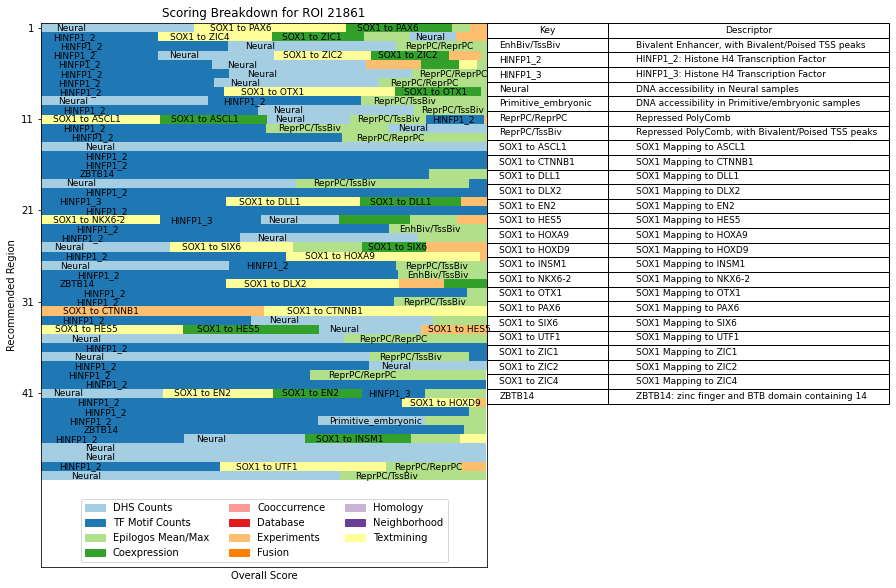

In [120]:
#sideways bar plots ordered by biggest component
all_metrics_arr = np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, 
                             database_arr, exper_arr, fusion_arr, homology_arr, 
                             neigh_arr, textmin_arr))

all_metrics_arr_top_100 = all_metrics_arr[:, top_region_inds[1:]]

metric_sum_top_100 = np.sum(all_metrics_arr_top_100, axis=0)

score_arr_top_100 = score_arr[top_region_inds[1:]]

metrics_bar_scaled = all_metrics_arr_top_100 / metric_sum_top_100 * score_arr_top_100 
metrics_bar_scaled = metrics_bar_scaled[:, :50]

metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

colors = np.array(['#a6cee3', '#1f78b4', '#b2df8a', '#33a02c', '#fb9a99', '#e31a1c', '#fdbf6f', '#ff7f00', 
                   '#cab2d6', '#6a3d9a', '#ffff99'])

#all string original and destination genes
all_arr_ori = np.array([coex_genes[0], cooccur_genes[0], database_genes[0], exper_genes[0], 
                        fusion_genes[0], homology_genes[0], neigh_genes[0], textmin_genes[0]])[:, top_region_inds[1:]]
all_arr_dest = np.array([coex_genes[1], cooccur_genes[1], database_genes[1], exper_genes[1], 
                         fusion_genes[1], homology_genes[1], neigh_genes[1], textmin_genes[1]])[:, top_region_inds[1:]]

#plotting
fig = plt.figure(figsize=(8, 10))
fig.patch.set_facecolor('white')
for i in range(11):
    plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[i], left=np.sum(metrics_bar_scaled_vals[:i], axis=0), 
             color=colors[metrics_bar_scaled_inds[i]], height=1, align='center')

#label top comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
top_factors = []
for i in range(len(metrics_bar_scaled_vals[0])):
    start_val = 0
    for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
        if ((metric==0) & (val>0)):
            DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
            if val / len(DHS_component_order[top_comp]) > 0.0119:
                plt.text(start_val + val/10, 
                         len(metrics_bar_scaled_vals[0])-1.35-i, 
                         DHS_component_order[top_comp], 
                         fontsize=9)
                top_factors.append(DHS_component_order[top_comp])
        elif ((metric==1) & (val>0)):
            TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
            top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
            if val / len(TF_component_order[top_comp]) > 0.0119:
                plt.text(start_val + val/10, 
                         len(metrics_bar_scaled_vals[0])-1.35-i, 
                         TF_component_order[top_comp], 
                         fontsize=9)
                top_factors.append(TF_component_order[top_comp])
        elif ((metric==2) & (val>0)):
            epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
            epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
            top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
            top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
            if val / len(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp]) > 0.0119:
                plt.text(start_val + val/10, 
                         len(metrics_bar_scaled_vals[0])-1.35-i, 
                         epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
                         fontsize=9)
                top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
        elif ((metric>2) & (val>0)):
            metric_ori_gene = geneID2name[all_arr_ori[metric-3][i]]
            metric_dest_gene = geneID2name[all_arr_dest[metric-3][i]]
            if val / len(metric_ori_gene + ' to ' + metric_dest_gene) > 0.0119:
                plt.text(start_val + val/10, 
                         len(metrics_bar_scaled_vals[0])-1.35-i, 
                         metric_ori_gene + ' to ' + metric_dest_gene, 
                         fontsize=9)
                top_factors.append(metric_ori_gene + ' to ' + metric_dest_gene)
        start_val+=val

#look up table
top_factors = np.unique(top_factors)
factor_bar_arr = []
for factor in top_factors:
    factor_l = factor.split('/')
    if len(factor_l) == 2: #epilogos
        if factor_l[0]==factor_l[1]:
            factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
        else:
            factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
    elif factor in DHSfact2descr: #DHS
        factor_bar_arr.append(DHSfact2descr[factor])
    elif factor in TFfact2descr: #TF motifs
        factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
    else:
        gene0, gene1 = factor.split(' to ')[0], factor.split(' to ')[1]
        factor_bar_arr.append(gene0 + ' Mapping to ' + gene1)
factor_bar_arr = np.array(factor_bar_arr)
lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
t = plt.table(lookup_table, 
              cellLoc='left',
              colLabels=['Key', 'Descriptor'],
              bbox=[1, 0.3, 0.9, 0.7], 
              colWidths=[0.15, 0.35])
t.auto_set_font_size(False)
t.set_fontsize(9)

plt.yticks(np.arange(9, 51, 10), np.flip(np.arange(1, 42, 10)))
plt.ylim([-10, 49.5])
plt.xticks([1])
h = []

for metric, c in zip(['DHS Counts', 'TF Motif Counts', 'Epilogos Mean/Max', 'Coexpression', 
                      'Cooccurrence', 'Database', 'Experiments', 'Fusion', 'Homology', 
                      'Neighborhood', 'Textmining'], colors):
    p = mpatches.Patch(color=c, label=metric)
    h.append(p)
plt.legend(handles=h, loc='lower center', ncol=3)
plt.xlabel('Overall Score')
plt.ylabel('Recommended Region')
title = 'Scoring Breakdown for ROI %s' %(roi)
plt.title(title)

In [230]:
# #sideways bar plots ordered by biggest component
# DHS_arr_top_100 = DHS_arr[top_region_inds[1:]]
# TF_arr_top_100 = TF_arr[top_region_inds[1:]]
# epilogos_arr_top_100 = epilogos_arr[top_region_inds[1:]]

# metric_sum_top_100 = DHS_arr_top_100 + TF_arr_top_100 + epilogos_arr_top_100

# score_arr_top_100 = score_arr[top_region_inds[1:]]

# DHS_arr_bar_scaled = DHS_arr_top_100 / metric_sum_top_100 * score_arr_top_100
# TF_arr_bar_scaled = TF_arr_top_100 / metric_sum_top_100 * score_arr_top_100
# epilogos_arr_bar_scaled = epilogos_arr_top_100 / metric_sum_top_100 * score_arr_top_100

# metrics_bar_scaled = np.array([DHS_arr_bar_scaled[:50], TF_arr_bar_scaled[:50], epilogos_arr_bar_scaled[:50]])
# metrics_bar_scaled_inds = np.argsort(-metrics_bar_scaled, axis=0)
# metrics_bar_scaled_vals = -np.sort(-metrics_bar_scaled, axis=0)

# colors = np.array(['#e41a1c', '#377eb8', '#4daf4a'])


# #plotting
# fig = plt.figure(figsize=(8, 10))
# fig.patch.set_facecolor('white')

# plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[0], color=colors[metrics_bar_scaled_inds[0]], height=1, align='center')
# plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[1], left=metrics_bar_scaled_vals[0], color=colors[metrics_bar_scaled_inds[1]], height=1, align='center')
# plt.barh(np.flip(np.arange(50)), metrics_bar_scaled_vals[2], left=metrics_bar_scaled_vals[0]+metrics_bar_scaled_vals[1], color=colors[metrics_bar_scaled_inds[2]], height=1, align='center')

# #label top comps
# DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
# TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
# epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
# epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])
# top_factors = []
# for i in range(len(metrics_bar_scaled_vals[0])):
#     start_val = 0
#     for metric, val in zip(metrics_bar_scaled_inds[:, i], metrics_bar_scaled_vals[:, i]):
#         if ((metric==0) & (val>0)):
#             DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
#             top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
#             plt.text(start_val + val/10, 
#                      len(metrics_bar_scaled_vals[0])-1.25-i, 
#                      DHS_component_order[top_comp], 
#                      fontsize=9)
#             top_factors.append(DHS_component_order[top_comp])
#         elif ((metric==1) & (val>0)):
#             TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
#             top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
#             plt.text(start_val + val/10, 
#                      len(metrics_bar_scaled_vals[0])-1.25-i, 
#                      TF_component_order[top_comp], 
#                      fontsize=9)
#             top_factors.append(TF_component_order[top_comp])
#         elif ((metric==2) & (val>0)):
#             epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
#             epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
#             top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
#             top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
#             plt.text(start_val + val/10, 
#                      len(metrics_bar_scaled_vals[0])-1.25-i, 
#                      epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp], 
#                      fontsize=9)
#             top_factors.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
#         start_val+=val

# #look up table
# top_factors = np.unique(top_factors)
# factor_bar_arr = []
# for factor in top_factors:
#     factor_l = factor.split('/')
#     if len(factor_l) == 2: #epilogos
#         if factor_l[0]==factor_l[1]:
#             factor_bar_arr.append(epilogosfact2descr[factor_l[0]])
#         else:
#             factor_bar_arr.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
#     elif factor in DHSfact2descr: #DHS
#         factor_bar_arr.append(DHSfact2descr[factor])
#     else: #TF motifs
#         factor_bar_arr.append(factor + ': ' + TFfact2descr[factor])
# factor_bar_arr = np.array(factor_bar_arr)
# lookup_table = np.hstack((top_factors.reshape((-1, 1)), factor_bar_arr.reshape((-1, 1))))
# t = plt.table(lookup_table, 
#               cellLoc='left',
#               colLabels=['Key', 'Descriptor'],
#               bbox=[1, 0.5, 0.9, 0.5], 
#               colWidths=[0.15, 0.35])
# t.auto_set_font_size(False)
# t.set_fontsize(9)

# plt.yticks(np.arange(9, 51, 10), np.flip(np.arange(1, 42, 10)))
# plt.ylim([-3, 49.5])
# plt.xticks([1])
# DHS_patch = mpatches.Patch(color='#e41a1c', label='DHS Counts')
# TF_patch = mpatches.Patch(color='#377eb8', label='TF Motif Counts')
# epilogos_patch = mpatches.Patch(color='#4daf4a', label='Epilogos Mean/Max')
# plt.legend(handles=[DHS_patch, TF_patch, epilogos_patch], loc='lower center', ncol=3)
# plt.xlabel('Overall Score')
# plt.ylabel('Recommended Region')
# title = 'Scoring Breakdown for ROI %s' %(roi)
# plt.title(title)

Breakdown of Factors with Top 100 Regions for ROI 21861 (chr13:112051600-112076600)


<Figure size 1440x720 with 0 Axes>

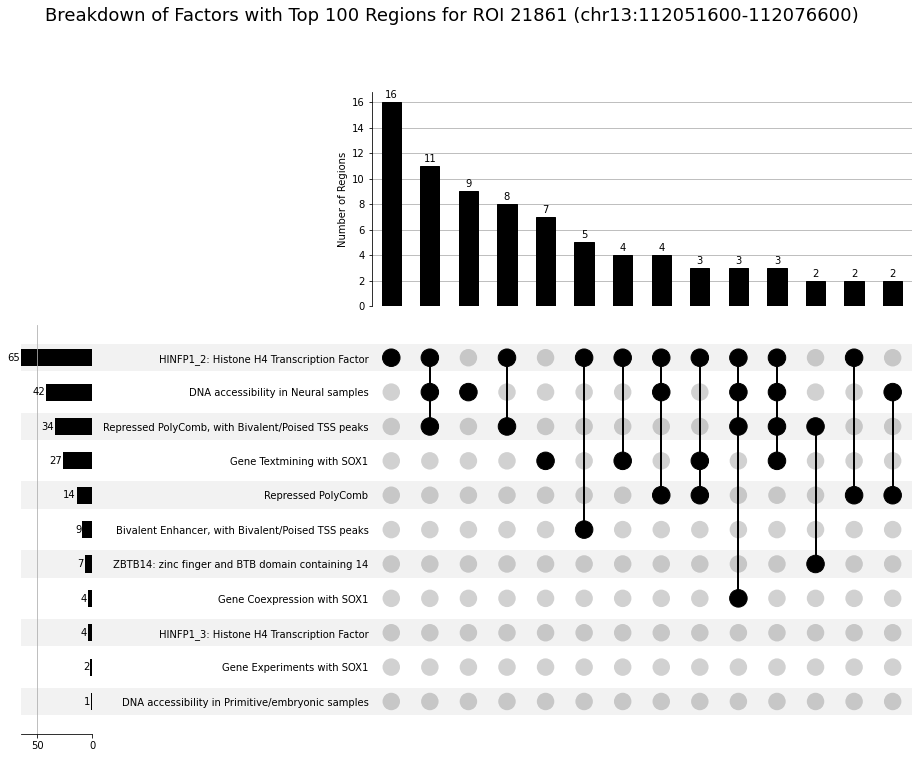

In [195]:
DHS_arr_top_100 = DHS_arr[top_region_inds[1:]]
TF_arr_top_100 = TF_arr[top_region_inds[1:]]
epilogos_arr_top_100 = epilogos_arr[top_region_inds[1:]]

all_metrics_arr = np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, 
                             database_arr, exper_arr, fusion_arr, homology_arr, 
                             neigh_arr, textmin_arr))
string_arr_top_100 = all_metrics_arr[3:, top_region_inds[1:]]
string_comp_order = ['Coexpression', 'Cooccurrence', 'Database', 'Experiments', 'Fusion', 'Homology', 
                     'Neighborhood', 'Textmining']

#roi comps
DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])

topfactor2region = {}
#find top comps for each metric/recommended region
for i in range(len(DHS_arr_top_100)):
    if DHS_arr_top_100[i] > 0:
        DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
        top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
        f = DHSfact2descr[DHS_component_order[top_comp]]
        if f not in topfactor2region:
            topfactor2region[f] = np.array([i])
        else:
            topfactor2region[f] = np.append(topfactor2region[f], [i])

for i in range(len(TF_arr_top_100)):
    if TF_arr_top_100[i] > 0:
        TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
        top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
        f = TF_component_order[top_comp] + ': ' + TFfact2descr[TF_component_order[top_comp]]
        if f not in topfactor2region:
            topfactor2region[f] = np.array([i])
        else:
            topfactor2region[f] = np.append(topfactor2region[f], [i])

for i in range(len(epilogos_arr_top_100)):
    if epilogos_arr_top_100[i] > 0:
        epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
        epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
        top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
        top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
        if top_mean_comp==top_max_comp:
            f = epilogosfact2descr[epilogos_component_order[top_mean_comp]]
        else:
            f = (epilogosfact2descr[epilogos_component_order[top_mean_comp]] + ', with ' + 
                 epilogosfact2descr[epilogos_component_order[top_max_comp]] + ' peaks')
        if f not in topfactor2region:
            topfactor2region[f] = np.array([i])
        else:
            topfactor2region[f] = np.append(topfactor2region[f], [i])

#STRING Scores
for i in range(len(string_arr_top_100[0, :])):
    if np.sum(string_arr_top_100[:, i]) > 0:
        string_i_rank = np.argsort(-string_arr_top_100[:, i])
        top_comp = string_i_rank[0]
        ori_gene = geneID2name[all_arr_ori[top_comp, i]]
        f = 'Gene ' + string_comp_order[top_comp] + ' with ' + ori_gene
        if f not in topfactor2region:
            topfactor2region[f] = np.array([i])
        else:
            topfactor2region[f] = np.append(topfactor2region[f], [i])
            
upset_data = upsetplot.from_contents(topfactor2region)
upset_data = upset_data.groupby(list(upset_data.index.names)).count()['id']

#sorting upset categories
upset_factors = np.array(upset_data.index.names)
upset_factor_counts = np.array([])
for i in range(len(upset_factors)):
    upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

fig = plt.figure(figsize=(20,10))

upsetplot.plot(sorted_upset_data, 
               sort_categories_by=None, 
               show_counts=True, 
               min_subset_size=2, 
               sort_by='cardinality', 
               element_size=50)

f = open(regions_path, 'r')
regions = f.readlines()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
f.close()

plt.ylabel('Number of Regions')
title='Breakdown of Factors with Top 100 Regions for ROI %s (%s)' %(roi, genome_coords)
plt.suptitle(title, fontsize=18)
print(title)

Factors Describing 95% of Top 100 Regions for ROI 21861 (chr13:112051600-112076600)


<Figure size 1440x720 with 0 Axes>

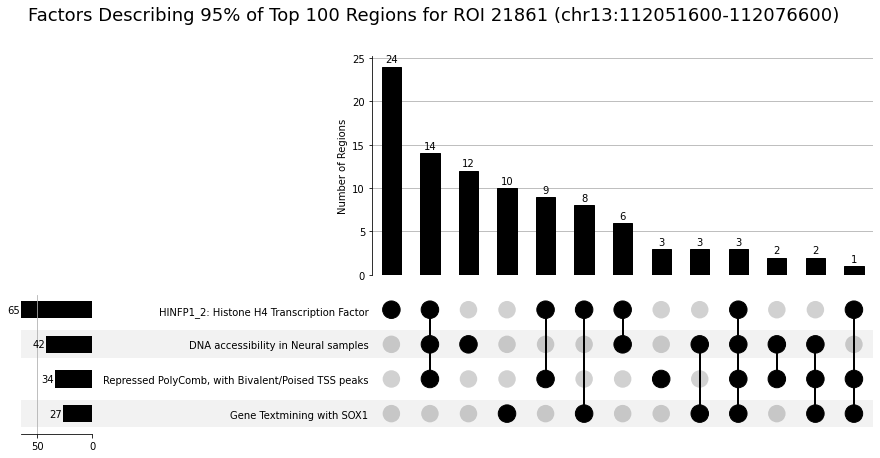

In [231]:
limiting_per = 95

overall_set = set()
topfactor2region_limited = {}
ind = 0
while len(overall_set) < limiting_per:
    factor = np.flip(list(sorted_upset_data.index.names))[ind]
    factor_set = set(list(topfactor2region[factor]))
    overall_set.update(factor_set)
    ind += 1
    topfactor2region_limited[factor] = topfactor2region[factor]
    
upset_data_limited = upsetplot.from_contents(topfactor2region_limited)
upset_data_limited = upset_data_limited.groupby(list(upset_data_limited.index.names)).count()['id']

#sorting upset categories
upset_factors_limited = np.array(upset_data_limited.index.names)
upset_factor_counts_limited = np.array([])
for i in range(len(upset_factors_limited)):
    upset_factor_counts_limited = np.append(upset_factor_counts_limited, np.sum(upset_data_limited.unstack(level=i)[True]))
upset_factors_sorted_limited = upset_factors_limited[np.argsort(upset_factor_counts_limited)]
sorted_upset_data_limited = upset_data_limited.reorder_levels(upset_factors_sorted_limited)


fig = plt.figure(figsize=(20,10))

upsetplot.plot(sorted_upset_data_limited, 
               sort_categories_by=None, 
               show_counts=True, 
               min_subset_size=1, 
               sort_by='cardinality', 
               element_size=50)

f = open(regions_path, 'r')
regions = f.readlines()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
f.close()

plt.ylabel('Number of Regions')
title='Factors Describing ' + str(limiting_per) + '%' + ' of Top 100 Regions for ROI %s (%s)' %(roi, genome_coords)
plt.suptitle(title, fontsize=18)
print(title)

In [303]:
# DHS_arr_top_100 = DHS_arr[top_region_inds[1:]]
# TF_arr_top_100 = TF_arr[top_region_inds[1:]]
# epilogos_arr_top_100 = epilogos_arr[top_region_inds[1:]]

# all_metrics_arr = np.vstack((DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, 
#                              database_arr, exper_arr, fusion_arr, homology_arr, 
#                              neigh_arr, textmin_arr))
# string_arr_top_100 = all_metrics_arr[3:, top_region_inds[1:]]
# string_comp_order = ['Coexpression', 'Cooccurrence', 'Database', 'Experiments', 'Fusion', 'Homology', 
#                      'Neighborhood', 'Textmining']

# #roi comps
# DHS_roi_rank = rankdata(-DHS_ooe[top_region_inds[0]])
# TF_roi_rank = rankdata(-TF_ooe[top_region_inds[0]])
# epilogos_roi_mean_rank = rankdata(-epilogos_ooe[top_region_inds[0]][:18])
# epilogos_roi_max_rank = rankdata(-epilogos_ooe[top_region_inds[0]][18:])

# #find top comps for each metric/recommended region
# DHS_top_comps_100 = []
# for i in range(len(DHS_arr_top_100)):
#     if DHS_arr_top_100[i] > 0:
#         DHS_i_rank = rankdata(-DHS_ooe[top_region_inds[i+1]])
#         top_comp = np.argsort((DHS_roi_rank+DHS_i_rank)/2)[0]
#         DHS_top_comps_100.append(DHS_component_order[top_comp])
#     else:
#         DHS_top_comps_100.append(np.nan)
# DHS_top_comps_100 = np.array(DHS_top_comps_100)

# TF_top_comps_100 = []
# for i in range(len(TF_arr_top_100)):
#     if TF_arr_top_100[i] > 0:
#         TF_i_rank = rankdata(-TF_ooe[top_region_inds[i+1]])
#         top_comp = np.argsort((TF_roi_rank+TF_i_rank)/2)[0]
#         TF_top_comps_100.append(TF_component_order[top_comp])
#     else:
#         TF_top_comps_100.append(np.nan)
# TF_top_comps_100 = np.array(TF_top_comps_100)

# epilogos_mean_top_comps_100 = []
# epilogos_max_top_comps_100 = []
# epilogos_top_comps_100 = []
# for i in range(len(epilogos_arr_top_100)):
#     if epilogos_arr_top_100[i] > 0:
#         epilogos_i_mean_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][:18])
#         epilogos_i_max_rank = rankdata(-epilogos_ooe[top_region_inds[i+1]][18:])
#         top_mean_comp = np.argsort((epilogos_roi_mean_rank + epilogos_i_mean_rank)/2)[0]
#         top_max_comp = np.argsort((epilogos_roi_max_rank + epilogos_i_max_rank)/2)[0]
#         epilogos_mean_top_comps_100.append(epilogos_component_order[top_mean_comp])
#         epilogos_max_top_comps_100.append(epilogos_component_order[top_max_comp])
#         epilogos_top_comps_100.append(epilogos_component_order[top_mean_comp] + '/' + epilogos_component_order[top_max_comp])
#     else:
#         epilogos_mean_top_comps_100.append(np.nan)
#         epilogos_max_top_comps_100.append(np.nan)
#         epilogos_top_comps_100.append(np.nan)
# epilogos_mean_top_comps_100 = np.array(epilogos_mean_top_comps_100)
# epilogos_max_top_comps_100 = np.array(epilogos_max_top_comps_100)
# epilogos_top_comps_100 = np.array(epilogos_top_comps_100)

# #STRING Scores
# string_top_comps_100 = []
# for i in range(len(string_arr_top_100[0, :])):
#     if np.sum(string_arr_top_100[:, i]) > 0:
#         string_i_rank = np.argsort(-string_arr_top_100[:, i])
#         top_comp = string_i_rank[0]
#         ori_gene = geneID2name[all_arr_ori[top_comp, i]]
#         string_top_comps_100.append('Gene ' + string_comp_order[top_comp] + ' with ' + ori_gene)
#     else:
#         string_top_comps_100.append(np.nan)
# string_top_comps_100 = np.array(string_top_comps_100)


# DHS_top_comps_100_unique = np.unique(DHS_top_comps_100[DHS_top_comps_100!='nan'])
# TF_top_comps_100_unique = np.unique(TF_top_comps_100[TF_top_comps_100!='nan'])
# # epilogos_mean_top_comps_100_unique = np.unique(epilogos_mean_top_comps_100[epilogos_mean_top_comps_100!='nan'])
# # epilogos_max_top_comps_100_unique = np.unique(epilogos_max_top_comps_100[epilogos_max_top_comps_100!='nan'])
# epilogos_top_comps_100_unique = np.unique(epilogos_top_comps_100[epilogos_top_comps_100!='nan'])
# string_top_comps_100_unique = np.unique(string_top_comps_100[string_top_comps_100!='nan'])

# labels = []
# count_data = []
# for DHS_factor in DHS_top_comps_100_unique:
#     for TF_factor in TF_top_comps_100_unique:
#         for epilogos_factor in epilogos_top_comps_100_unique:
#             for string_factor in string_top_comps_100_unique:
#                 #all 4
#                 labels.append([DHS_factor, TF_factor, epilogos_factor, string_factor])
#                 count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                         (TF_top_comps_100==TF_factor) &
#                                                                         (epilogos_top_comps_100==epilogos_factor) &
#                                                                         (string_top_comps_100==string_factor))]))
#                 #3/4
#                 if [DHS_factor, TF_factor, string_factor] not in labels:
#                     labels.append([DHS_factor, TF_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [DHS_factor, epilogos_factor, string_factor] not in labels:
#                     labels.append([DHS_factor, epilogos_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [TF_factor, epilogos_factor, string_factor] not in labels:
#                     labels.append([TF_factor, epilogos_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [DHS_factor, TF_factor, epilogos_factor] not in labels:
#                     labels.append([DHS_factor, TF_factor, epilogos_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100=='nan'))]))
                
#                 #2/4
#                 if [DHS_factor, string_factor] not in labels:
#                     labels.append([DHS_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [epilogos_factor, string_factor] not in labels:
#                     labels.append([epilogos_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [TF_factor, string_factor] not in labels:
#                     labels.append([TF_factor, string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100==string_factor))]))
#                 if [DHS_factor, TF_factor] not in labels:
#                     labels.append([DHS_factor, TF_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100=='nan'))]))
#                 if [DHS_factor, epilogos_factor] not in labels:
#                     labels.append([DHS_factor, epilogos_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100=='nan'))]))
#                 if [TF_factor, epilogos_factor] not in labels:
#                     labels.append([TF_factor, epilogos_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100=='nan'))]))
#                 #1/4
#                 if [DHS_factor] not in labels:
#                     labels.append([DHS_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100==DHS_factor) & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100=='nan'))]))
#                 if [TF_factor] not in labels:
#                     labels.append([TF_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100==TF_factor) &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100=='nan'))]))
#                 if [epilogos_factor] not in labels:
#                     labels.append([epilogos_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100==epilogos_factor) &
#                                                                             (string_top_comps_100=='nan'))]))
#                 if [string_factor] not in labels:
#                     labels.append([string_factor])
#                     count_data.append(len(np.arange(len(DHS_top_comps_100))[((DHS_top_comps_100=='nan') & 
#                                                                             (TF_top_comps_100=='nan') &
#                                                                             (epilogos_top_comps_100=='nan') &
#                                                                             (string_top_comps_100==string_factor))]))
# count_data = np.array(count_data)
# #get descriptor labels
# descriptor_labels = []
# for combo in labels:
#     combo_labels = []
#     for factor in combo:
#         factor_l = factor.split('/')
#         if len(factor_l) == 2: #epilogos
#             if factor_l[0]==factor_l[1]:
#                 combo_labels.append(epilogosfact2descr[factor_l[0]])
#             else:
#                 combo_labels.append(epilogosfact2descr[factor_l[0]] + ', with ' + epilogosfact2descr[factor_l[1]] + ' peaks')
#         elif factor in DHSfact2descr: #DHS
#             combo_labels.append(DHSfact2descr[factor])
#         elif factor in TFfact2descr: #TF motifs
#             combo_labels.append(factor + ': ' + TFfact2descr[factor])
#         else:
#             combo_labels.append(factor)
#     descriptor_labels.append(combo_labels)
# descriptor_labels = np.array(descriptor_labels, dtype=object)

# upset_data = upsetplot.from_memberships(descriptor_labels, data=count_data)

# #sorting upset categories
# upset_factors = np.array(upset_data.index.names)
# upset_factor_counts = np.array([])
# for i in range(len(upset_factors)):
#     upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
# upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
# sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

# fig = plt.figure(figsize=(20,10))

# upsetplot.plot(sorted_upset_data, 
#                sort_categories_by=None, 
#                show_counts=True, 
#                min_subset_size=2, 
#                sort_by='cardinality', 
#                element_size=50)

# f = open(regions_path, 'r')
# regions = f.readlines()
# regions = regions[roi].strip().split('\t')
# genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
# f.close()

# plt.ylabel('Number of Regions')
# title='Breakdown of Factors with Top 100 Regions for ROI %s (%s)' %(roi, genome_coords)
# plt.suptitle(title, fontsize=18)
# print(title)

Text(0.5, 1.0, 'Gene Descriptions for ROI 21861 (chr13:112051600-112076600) and Top 100 Regions')

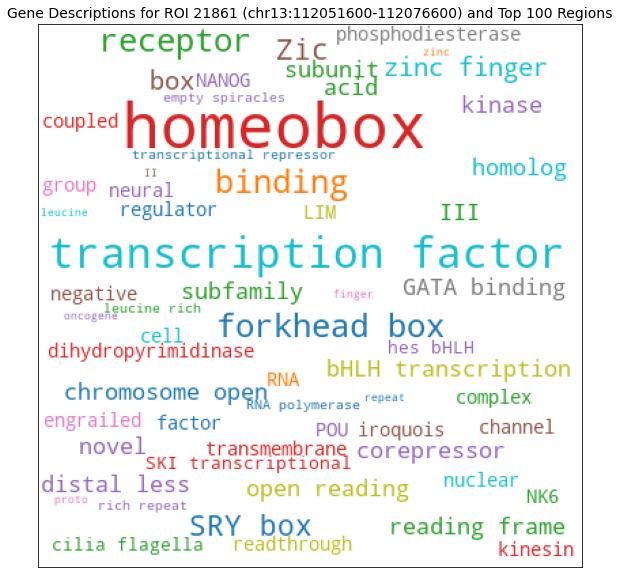

In [123]:
descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.genedescriptorooe.hdf5'

descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
term_roi_counts = descriptor_hdf5['term_roi_counts'][roi]
descriptor_hdf5.close()

#word cloud
gene_descriptions = ''
for i in top_region_inds:
    line = re.split(';|\t|\|', mapped_genes[i].strip())
    descriptions = line[7::5]
    gene_descriptions += ' '.join(descriptions) + ' '

gene_descriptions_test0 = gene_descriptions
#getting rid of descriptors that occur less than x times or not in term list
gene_descriptions = gene_descriptions.replace('(', '').replace(')', '')
for descriptor in np.unique(gene_descriptions.split()):
    descriptor = descriptor.strip(',')
    descriptor_ind = np.where(gene_descriptor_arr==descriptor.lower())[0]
    if len(descriptor_ind) == 1:
        descriptor_count = term_roi_counts[descriptor_ind[0]]
        if descriptor_count < 2:
            gene_descriptions = gene_descriptions.replace(' ' + descriptor + ' ', ' ')
    else:
        gene_descriptions = gene_descriptions.replace(' ' + descriptor + ' ', ' ')

    
fig = plt.figure(figsize=(10, 10))
fig.patch.set_facecolor('white')

stop_words = ['of', 'the', 'a', 'protein', 'and', 'like', 'with', 'domain', 'containing', 'member', 
              'associated', 'family', 'non', 'paired', 'one', 'two', 'three', 'four', 'five', 'six', 
              'seven', 'eight', 'nine', 'ten', 'class', 'related', 'bound', 'type']

gene_wc = WordCloud(width=400, 
                    height=400, 
                    min_word_length=2, 
                    min_font_size=6, 
                    background_color='white', 
                    colormap='tab10', 
                    stopwords=stop_words, 
                    relative_scaling=0.5, 
                    prefer_horizontal=1, 
                    collocation_threshold=15).generate(gene_descriptions)
plt.imshow(gene_wc)

plt.xticks([])
plt.yticks([])

f = open(regions_path, 'r')
regions = f.readlines()
f.close()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
title = 'Gene Descriptions for ROI %s (%s) and Top 100 Regions' %(roi, genome_coords)
plt.title(title, fontsize=14)

In [210]:
# #calculating total counts for all terms together - rewritten 20220713 (original cell got deleted)?
# total_term_counts = np.sum(term_full_counts)

In [211]:
# descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220712.genedescriptorooe.hdf5'

# descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
# term_roi_ooe = descriptor_hdf5['term_roi_ooe'][roi]
# term_roi_counts = descriptor_hdf5['term_roi_counts'][roi]
# descriptor_hdf5.close()

# gene_descriptions = ''
# roi_genes = []
# for i in top_region_inds:
#     line = re.split(';|\t|\|', mapped_genes[i].strip())
#     descriptions = line[7::5]
#     roi_genes.append(line[6::5])
#     gene_descriptions += ' '.join(descriptions) + ' '
    
# gene_descriptions_test1 = gene_descriptions
# gene_descriptions = gene_descriptions.replace('(', '').replace(')', '').split()

# terms_to_test = []
# for descriptor in np.unique(gene_descriptions):
#     descriptor = descriptor.strip(',')
#     if descriptor.lower() in gene_descriptor_arr:
#         terms_to_test.append(descriptor)

# roi_descriptor_dict = {}
# for descriptor in terms_to_test:
#     descriptor_ind = np.where(gene_descriptor_arr==descriptor.lower())[0][0]
#     term_count_in_region = term_roi_counts[descriptor_ind]
#     not_term_count_in_region = np.sum(term_roi_counts) - term_count_in_region
#     term_count_in_not_region = np.sum(term_full_counts[:, descriptor_ind]) - term_count_in_region
#     not_term_count_in_not_region = total_term_counts - term_count_in_region - not_term_count_in_region - term_count_in_not_region
#     conting = [[term_count_in_region, not_term_count_in_region], 
#                [term_count_in_not_region, not_term_count_in_not_region]]
#     odds, pval = fisher_exact(conting, alternative='greater')
    
#     #bonferroni correction and removing negative log2 vals
#     if ((pval < (0.05 / len(terms_to_test))) & (np.log2(term_roi_ooe[descriptor_ind]) > 0)):
#         roi_descriptor_dict[descriptor] = np.log2(term_roi_ooe[descriptor_ind])
        

# fig = plt.figure(figsize=(10, 10))
# fig.patch.set_facecolor('white')

# gene_wc = WordCloud(width=400, 
#                     height=400, 
#                     min_word_length=2, 
#                     min_font_size=6,
#                     background_color='white', 
#                     colormap='tab10', 
#                     relative_scaling=0.5, 
#                     prefer_horizontal=1).generate_from_frequencies(roi_descriptor_dict)

# plt.imshow(gene_wc)

# plt.xticks([])
# plt.yticks([])

# f = open(regions_path, 'r')
# regions = f.readlines()
# f.close()
# regions = regions[roi].strip().split('\t')
# genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
# title = 'Significant OOE Gene Descriptions for\nROI %s (%s) and Top 100 Regions' %(roi, genome_coords)
# plt.title(title, fontsize=14)

In [124]:
class SimpleGroupedColorFunc(object):
    #from Andreas Mueller, https://amueller.github.io/word_cloud/auto_examples/colored_by_group.html
    """Create a color function object which assigns EXACT colors
       to certain words based on the color to words mapping

       Parameters
       ----------
       color_to_words : dict(str -> list(str))
         A dictionary that maps a color to the list of words.
    """
    def __init__(self, color_to_words):
        self.word_to_color = {word: color
                              for (color, words) in color_to_words.items()
                              for word in words}

    def __call__(self, word, **kwargs):
        return self.word_to_color.get(word)

Text(0.5, 1.0, 'Significant OOE Gene Descriptions for\nROI 21861 (chr13:112051600-112076600) and Top 100 Regions')

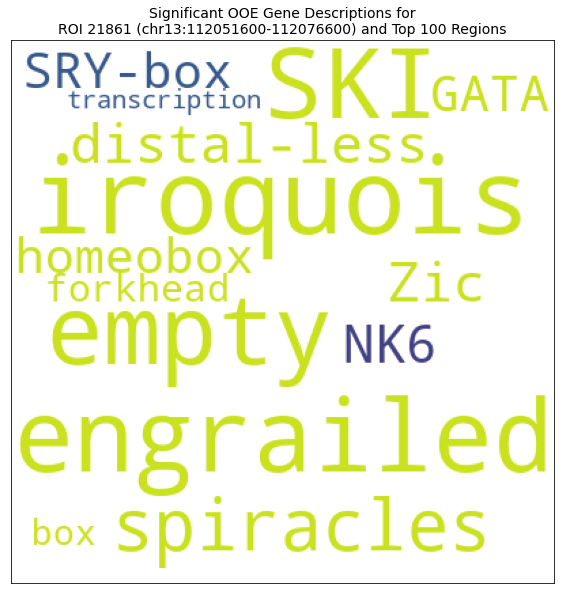

In [125]:
#could also filter out terms with all 0 significant ooe values

descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220713.genedescriptorooe.sig.hdf5'

descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
term_sig_log2ooe = descriptor_hdf5['sig_term_roi_log2ooe'][roi]
term_sig_counts = descriptor_hdf5['sig_term_roi_counts'][roi]
descriptor_hdf5.close()

term_order_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220714.genetermorder.cosine.ward.npy'
term_order = np.load(term_order_path)

colors = cm.get_cmap('viridis', len(term_order)).colors 

gene_descriptions = ''
roi_genes = []
for i in top_region_inds:
    line = re.split(';|\t|\|', mapped_genes[i].strip())
    descriptions = line[7::5]
    roi_genes.append(line[6::5])
    gene_descriptions += ' '.join(descriptions) + ' '
    
gene_descriptions_test1 = gene_descriptions
gene_descriptions = gene_descriptions.replace('(', '').replace(')', '').split()

terms_to_test = []
for descriptor in np.unique(gene_descriptions):
    descriptor = descriptor.strip(',')
    if descriptor.lower() in gene_descriptor_arr:
        terms_to_test.append(descriptor)

roi_descriptor_dict = {}
color2terms = {}
for descriptor in terms_to_test:
    descriptor_ind = np.where(gene_descriptor_arr==descriptor.lower())[0][0]
    #finding if marked significant
    if term_sig_log2ooe[descriptor_ind] > 0:
        #add term to plot
        roi_descriptor_dict[descriptor] = term_sig_log2ooe[descriptor_ind]
        #find color
        cluster_ind = np.where(term_order==descriptor_ind)[0][0]
        c = (colors[cluster_ind][0], colors[cluster_ind][1], colors[cluster_ind][2])
        c = matplotlib.colors.to_hex(c)
        if c not in color2terms:
            color2terms[c] = np.array([descriptor])
        else:
            color2terms[c] = np.append(color2terms[c], [descriptor])
        

fig = plt.figure(figsize=(10, 10))
fig.patch.set_facecolor('white')

gene_wc = WordCloud(width=400, 
                    height=400, 
                    min_word_length=2, 
                    min_font_size=6,
                    background_color='white', 
                    colormap='tab10', 
                    relative_scaling=0.5, 
                    prefer_horizontal=1).generate_from_frequencies(roi_descriptor_dict)

color_func = SimpleGroupedColorFunc(color2terms)

gene_wc.recolor(color_func=color_func)

plt.imshow(gene_wc)

plt.xticks([])
plt.yticks([])

f = open(regions_path, 'r')
regions = f.readlines()
f.close()
regions = regions[roi].strip().split('\t')
genome_coords = regions[0] + ':' + regions[1] + '-' + regions[2]
title = 'Significant OOE Gene Descriptions for\nROI %s (%s) and Top 100 Regions' %(roi, genome_coords)
plt.title(title, fontsize=14)

In [86]:
#to generate many word clouds
descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
regions_term_counts = descriptor_hdf5['sig_term_roi_counts'][:]
descriptor_hdf5.close()

regions_with_terms = np.where(np.sum(regions_term_counts, axis=1)!=0)[0]

regions_path = '/home/ctrader/region_similarity/data/Altius_25kb_hg38_maxMean_CT20220613.sorted.c1t3.bed'
descriptorooe_hdf5_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220713.genedescriptorooe.sig.hdf5'
term_order_path = '/home/ctrader/region_similarity/data/regions_25kb_CT20220714.genetermorder.cosine.ward.npy'
term_order = np.load(term_order_path)
colors = cm.get_cmap('viridis', len(term_order)).colors 

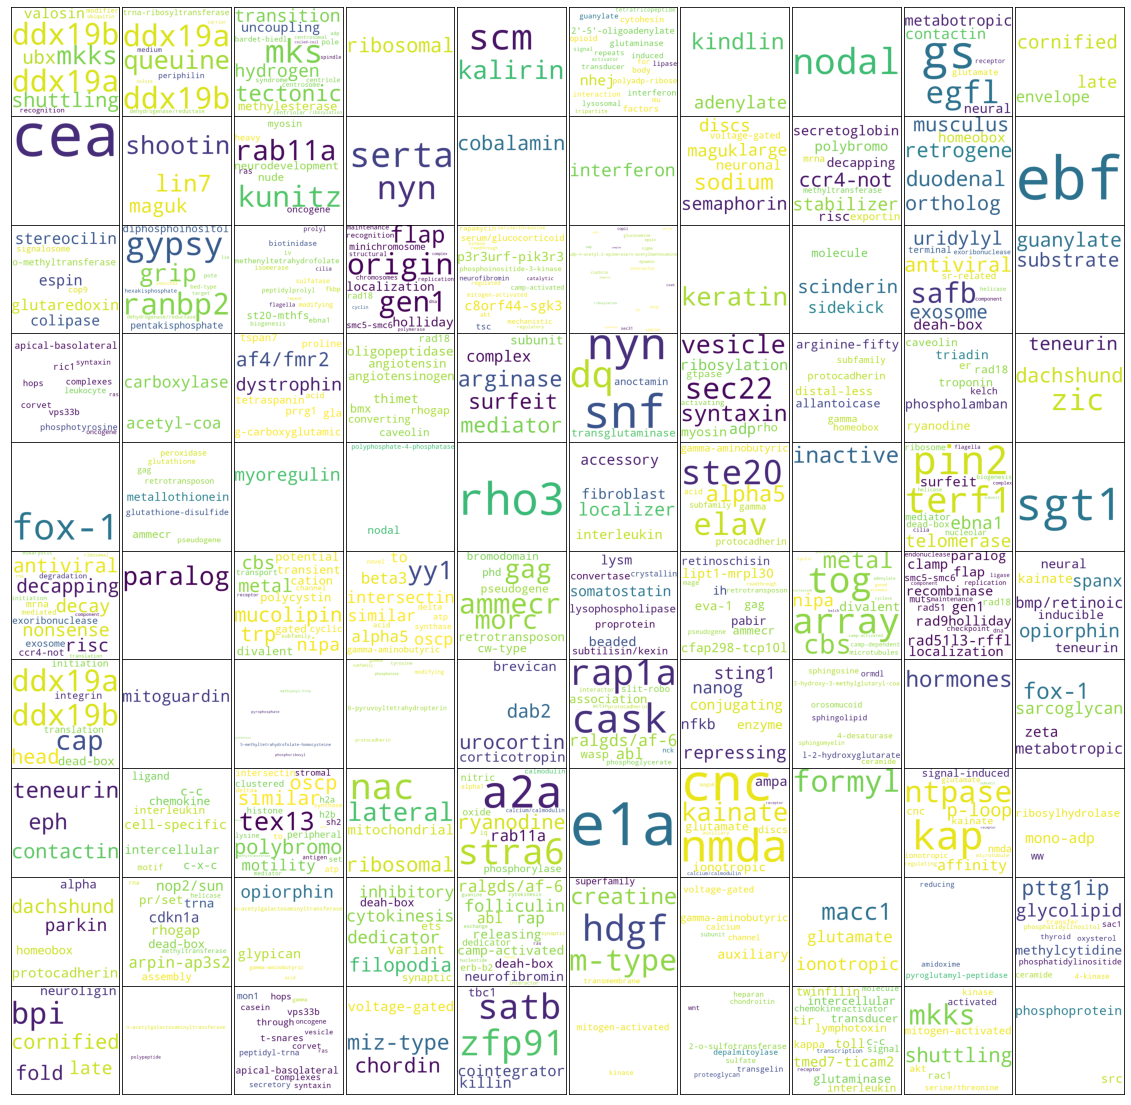

In [91]:
###generating many word clouds

#could also filter out terms with all 0 significant ooe values


fig, axes = plt.subplots(nrows=10, ncols=10, figsize=(20,20))
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0, hspace=0)

axes = axes.flatten()

rois = random.sample(set(regions_with_terms), k=100)

for ax, i in zip(axes, range(len(axes))):

    roi = rois[i]

    descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
    term_sig_log2ooe = descriptor_hdf5['sig_term_roi_log2ooe'][roi]
    descriptor_hdf5.close()
    
    roi_descriptor_dict = {}
    color2terms = {}
    term_inds_to_find = np.where(term_sig_log2ooe!=0)[0]

    for descriptor_ind in term_inds_to_find:
        descriptor = gene_descriptor_arr[descriptor_ind]
        #finding if marked significant
        if term_sig_log2ooe[descriptor_ind] > 0:
            #add term to plot
            roi_descriptor_dict[descriptor] = term_sig_log2ooe[descriptor_ind]
            #find color
            cluster_ind = np.where(term_order==descriptor_ind)[0][0]
            c = (colors[cluster_ind][0], colors[cluster_ind][1], colors[cluster_ind][2])
            c = matplotlib.colors.to_hex(c)
            if c not in color2terms:
                color2terms[c] = np.array([descriptor])
            else:
                color2terms[c] = np.append(color2terms[c], [descriptor])

    gene_wc = WordCloud(width=400, 
                        height=400, 
                        min_word_length=2, 
                        min_font_size=6,
                        background_color='white', 
                        colormap='tab10', 
                        relative_scaling=0.5, 
                        prefer_horizontal=1).generate_from_frequencies(roi_descriptor_dict)

    color_func = SimpleGroupedColorFunc(color2terms)

    gene_wc.recolor(color_func=color_func)

    ax.imshow(gene_wc)

    ax.set_xticks([])
    ax.set_yticks([])

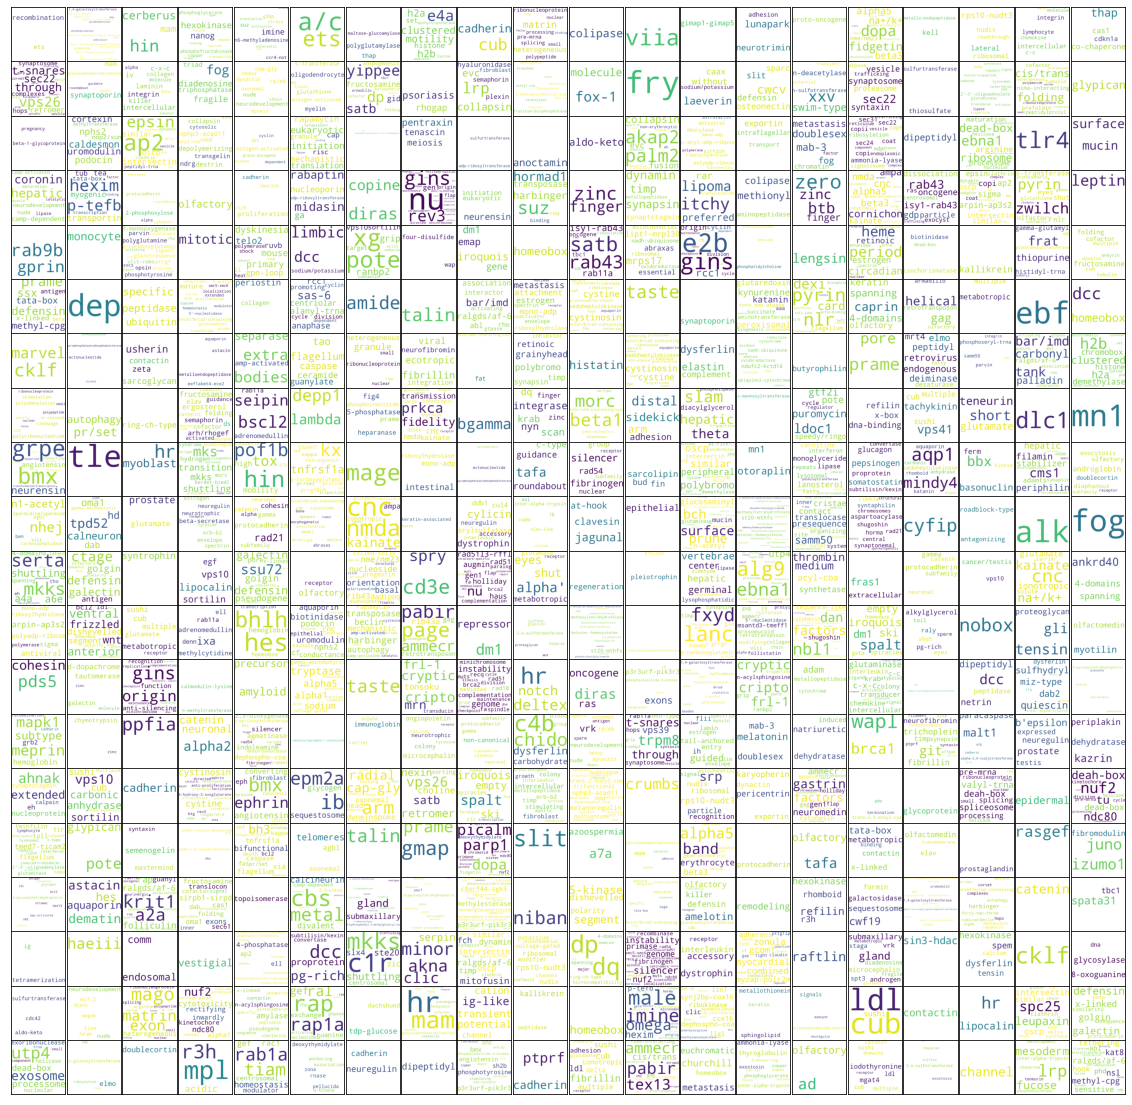

In [232]:
fig, axes = plt.subplots(nrows=20, ncols=20, figsize=(20,20))
fig.patch.set_facecolor('white')
fig.subplots_adjust(wspace=0, hspace=0)

axes = axes.flatten()

rois = random.sample(set(regions_with_terms), k=400)

for ax, i in zip(axes, range(len(axes))):

    roi = rois[i]

    descriptor_hdf5 = h5py.File(descriptorooe_hdf5_path, 'r')
    term_sig_log2ooe = descriptor_hdf5['sig_term_roi_log2ooe'][roi]
    descriptor_hdf5.close()
    
    roi_descriptor_dict = {}
    color2terms = {}
    term_inds_to_find = np.where(term_sig_log2ooe!=0)[0]

    for descriptor_ind in term_inds_to_find:
        descriptor = gene_descriptor_arr[descriptor_ind]
        #finding if marked significant
        if term_sig_log2ooe[descriptor_ind] > 0:
            #add term to plot
            roi_descriptor_dict[descriptor] = term_sig_log2ooe[descriptor_ind]
            #find color
            cluster_ind = np.where(term_order==descriptor_ind)[0][0]
            c = (colors[cluster_ind][0], colors[cluster_ind][1], colors[cluster_ind][2])
            c = matplotlib.colors.to_hex(c)
            if c not in color2terms:
                color2terms[c] = np.array([descriptor])
            else:
                color2terms[c] = np.append(color2terms[c], [descriptor])

    gene_wc = WordCloud(width=400, 
                        height=400, 
                        min_word_length=2, 
                        min_font_size=6,
                        background_color='white', 
                        colormap='tab10', 
                        relative_scaling=0.5, 
                        prefer_horizontal=1).generate_from_frequencies(roi_descriptor_dict)

    color_func = SimpleGroupedColorFunc(color2terms)

    gene_wc.recolor(color_func=color_func)

    ax.imshow(gene_wc)

    ax.set_xticks([])
    ax.set_yticks([])

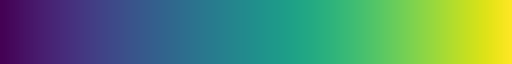

In [88]:
cm.get_cmap('viridis', len(term_order))

In [226]:
# gene_descriptions = ''
# roi_genes = []
# for i in top_region_inds:
#     line = re.split(';|\t|\|', mapped_genes[i].strip())
#     descriptions = line[7::5]
#     print(np.where(top_region_inds==i)[0][0])
#     print(line[6::5])
#     print(descriptions)
#     roi_genes.append(line[6::5])
#     gene_descriptions += ''.join(descriptions) + ' '

All Regions Scoring Breakdown for ROI 21861


<Figure size 720x720 with 0 Axes>

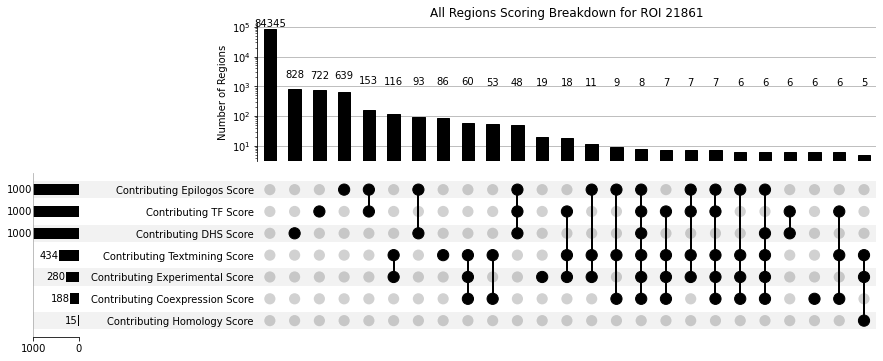

In [280]:
data_for_upset = np.array([DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, database_arr, 
                            exper_arr, fusion_arr, homology_arr, neigh_arr, textmin_arr]).T
labels_for_upset = ['Contributing DHS Score', 'Contributing TF Score', 'Contributing Epilogos Score', 
                    'Contributing Coexpression Score', 'Contributing Cooccurrence Score', 'Contributing Database Score', 
                    'Contributing Experimental Score', 'Contributing Fusion Score', 'Contributing Homology Score', 
                    'Contributing Neighborhood Score', 'Contributing Textmining Score']

bool_for_upset = np.where(data_for_upset>0, True, False)
indicators_for_upset = {}
for i, l in zip(range(len(labels_for_upset)), labels_for_upset):
    indicators_for_upset[l] = bool_for_upset[:, i]
    
upset_data = upsetplot.from_indicators(indicators_for_upset)
upset_data = upset_data.groupby(list(upset_data.index.names)).count()

#sorting upset categories
upset_factors = np.array(upset_data.index.names)
upset_factor_counts = np.array([])
for i in range(len(upset_factors)):
    upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

fig = plt.figure(figsize=(10,10))

upsetplot.plot(sorted_upset_data, sort_categories_by=None, min_subset_size=5, show_counts=True, sort_by='cardinality')
plt.yscale('log')

plt.ylabel('Number of Regions')
title='All Regions Scoring Breakdown for ROI %s' %(roi)
plt.title(title)
print(title)
plt.show()

Top 100 Similar Regions Scoring Breakdown for ROI 21861


<Figure size 720x720 with 0 Axes>

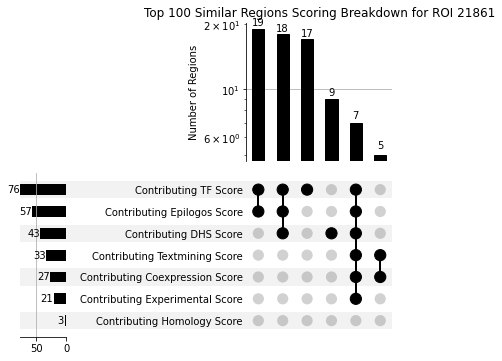

In [281]:
data_for_upset = np.array([DHS_arr, TF_arr, epilogos_arr, coex_arr, cooccur_arr, database_arr, 
                            exper_arr, fusion_arr, homology_arr, neigh_arr, textmin_arr]).T
data_for_upset = data_for_upset[top_region_inds[1:]]
labels_for_upset = ['Contributing DHS Score', 'Contributing TF Score', 'Contributing Epilogos Score', 
                    'Contributing Coexpression Score', 'Contributing Cooccurrence Score', 'Contributing Database Score', 
                    'Contributing Experimental Score', 'Contributing Fusion Score', 'Contributing Homology Score', 
                    'Contributing Neighborhood Score', 'Contributing Textmining Score']

bool_for_upset = np.where(data_for_upset>0, True, False)
indicators_for_upset = {}
for i, l in zip(range(len(labels_for_upset)), labels_for_upset):
    indicators_for_upset[l] = bool_for_upset[:, i]
    
upset_data = upsetplot.from_indicators(indicators_for_upset)
upset_data = upset_data.groupby(list(upset_data.index.names)).count()

#sorting upset categories
upset_factors = np.array(upset_data.index.names)
upset_factor_counts = np.array([])
for i in range(len(upset_factors)):
    upset_factor_counts = np.append(upset_factor_counts, np.sum(upset_data.unstack(level=i)[True]))
upset_factors_sorted = upset_factors[np.argsort(upset_factor_counts)]
sorted_upset_data = upset_data.reorder_levels(upset_factors_sorted)

fig = plt.figure(figsize=(10,10))

upsetplot.plot(sorted_upset_data, sort_categories_by=None, min_subset_size=5, show_counts=True, sort_by='cardinality')
plt.yscale('log')

plt.ylabel('Number of Regions')
title='Top 100 Similar Regions Scoring Breakdown for ROI %s' %(roi)
plt.title(title)
print(title)
plt.show()

In [30]:
# #all regions
# mask_all3 = (DHS_arr!=0) & (TF_arr!=0) & (epilogos_arr!=0)
# mask_dt = (DHS_arr!=0) & (TF_arr!=0) & (epilogos_arr==0)
# mask_de = (DHS_arr!=0) & (TF_arr==0) & (epilogos_arr!=0)
# mask_et = (DHS_arr==0) & (TF_arr!=0) & (epilogos_arr!=0)
# mask_d = (DHS_arr!=0) & (TF_arr==0) & (epilogos_arr==0)
# mask_t = (DHS_arr==0) & (TF_arr!=0) & (epilogos_arr==0)
# mask_e = (DHS_arr==0) & (TF_arr==0) & (epilogos_arr!=0)
# mask_none = (DHS_arr==0) & (TF_arr==0) & (epilogos_arr==0)

# count_data = [len(DHS_arr[mask_all3]), 
#               len(DHS_arr[mask_dt]), 
#               len(DHS_arr[mask_de]),
#               len(DHS_arr[mask_et]),
#               len(DHS_arr[mask_d]),
#               len(DHS_arr[mask_t]),
#               len(DHS_arr[mask_e]),
#               len(DHS_arr[mask_none])]

# max_count = np.max(count_data)

# upset_data = upsetplot.from_memberships(
#     [['Non-zero DHS Score', 'Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
#      ['Non-zero DHS Score', 'Non-zero TF Motif Score'],
#      ['Non-zero DHS Score', 'Non-zero Epilogos Score'],
#      ['Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
#      ['Non-zero DHS Score'],
#      ['Non-zero TF Motif Score'],
#      ['Non-zero Epilogos Score'],
#      []
#      ],
#      data=count_data
# )

# comb_score_annot = np.array([np.mean(score_arr[mask_none]), np.mean(score_arr[mask_d]), np.mean(score_arr[mask_e]), 
#                              np.mean(score_arr[mask_t]), np.mean(score_arr[mask_de]), np.mean(score_arr[mask_dt]),
#                              np.mean(score_arr[mask_et]), np.mean(score_arr[mask_all3])])

# individual_score_annot = np.array([0, 
#                                    np.mean(DHS_arr[mask_d]), 
#                                    np.mean(epilogos_arr[mask_e]),
#                                    np.mean(TF_arr[mask_t]), 
#                                    np.mean([DHS_arr[mask_de], epilogos_arr[mask_de]]), 
#                                    np.mean([DHS_arr[mask_dt], TF_arr[mask_dt]]), 
#                                    np.mean([epilogos_arr[mask_et], TF_arr[mask_et]]),
#                                    np.mean([DHS_arr[mask_all3], epilogos_arr[mask_all3], TF_arr[mask_all3]])])

# all3_individual_scores = np.array([np.mean(TF_arr[mask_all3]), 
#                                    np.mean(epilogos_arr[mask_all3]), 
#                                    np.mean(DHS_arr[mask_all3])])


# fig = plt.figure(figsize=(10,10))

# upsetplot.plot(upset_data, sort_categories_by=None)
# plt.yscale('log')

# #annotate columns
# comb_y_pos=0.001
# for score, x_pos in zip(np.round(comb_score_annot, 4), np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')

# plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')

# indi_y_pos=0.00005
# for score, x_pos in zip(np.round(individual_score_annot, 4), np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, indi_y_pos, score, rotation=90, weight='roman')
    
# plt.text(-5.75, indi_y_pos, 'Average Individual Score', weight='roman')
    
# adjustment = 0.13
# for score, y_pos in zip(np.round(all3_individual_scores, 4), np.array([0.005, 0.035, 0.065])+adjustment):
#     plt.text(0.55, y_pos, score, weight='roman', transform=fig.transFigure)
    
# plt.text(0.55, 0.095 + adjustment, 'All 3\nMetric\nScores', weight='roman', transform=fig.transFigure)

# plt.ylabel('Number of Regions')
# title='All Regions Scoring Breakdown for ROI %s' %(roi)
# plt.title(title)
# print(title)
# plt.show()

In [31]:
# #top 100
# mask_100_all3 = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]!=0)
# mask_100_dt = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]==0)
# mask_100_de = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]!=0)
# mask_100_et = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]!=0)
# mask_100_d = (DHS_arr[top_region_inds[1:]]!=0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]==0)
# mask_100_t = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]!=0) & (epilogos_arr[top_region_inds[1:]]==0)
# mask_100_e = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]!=0)
# mask_100_none = (DHS_arr[top_region_inds[1:]]==0) & (TF_arr[top_region_inds[1:]]==0) & (epilogos_arr[top_region_inds[1:]]==0)

# count_data = [len(DHS_arr[top_region_inds[1:]][mask_100_all3]), 
#               len(DHS_arr[top_region_inds[1:]][mask_100_dt]), 
#               len(DHS_arr[top_region_inds[1:]][mask_100_de]),
#               len(DHS_arr[top_region_inds[1:]][mask_100_et]),
#               len(DHS_arr[top_region_inds[1:]][mask_100_d]),
#               len(DHS_arr[top_region_inds[1:]][mask_100_t]),
#               len(DHS_arr[top_region_inds[1:]][mask_100_e]),
#               len(DHS_arr[top_region_inds[1:]][mask_100_none])]

# max_count_100 = np.max(count_data)

# upset_data_top100 = upsetplot.from_memberships(
#     [['Non-zero DHS Score', 'Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
#      ['Non-zero DHS Score', 'Non-zero TF Motif Score'],
#      ['Non-zero DHS Score', 'Non-zero Epilogos Score'],
#      ['Non-zero TF Motif Score', 'Non-zero Epilogos Score'],
#      ['Non-zero DHS Score'],
#      ['Non-zero TF Motif Score'],
#      ['Non-zero Epilogos Score'],
#      []
#      ],
#      data=count_data
# )

# comb_score_annot_100 = np.array([np.nan, 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_d]), 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_e]), 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_t]), 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_de]), 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_dt]),
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_et]), 
#                                  np.mean(score_arr[top_region_inds[1:]][mask_100_all3])])

# individual_score_annot_100 = np.array([np.nan, 
#                                        np.mean(DHS_arr[top_region_inds[1:]][mask_100_d]), 
#                                        np.mean(epilogos_arr[top_region_inds[1:]][mask_100_e]),
#                                        np.mean(TF_arr[top_region_inds[1:]][mask_100_t]), 
#                                        np.mean([DHS_arr[top_region_inds[1:]][mask_100_de], 
#                                                 epilogos_arr[top_region_inds[1:]][mask_100_de]]), 
#                                        np.mean([DHS_arr[top_region_inds[1:]][mask_100_dt], 
#                                                 TF_arr[top_region_inds[1:]][mask_100_dt]]), 
#                                        np.mean([epilogos_arr[top_region_inds[1:]][mask_100_et], 
#                                                 TF_arr[top_region_inds[1:]][mask_100_et]]),
#                                        np.mean([DHS_arr[top_region_inds[1:]][mask_100_all3], 
#                                                 epilogos_arr[top_region_inds[1:]][mask_100_all3], 
#                                                 TF_arr[top_region_inds[1:]][mask_100_all3]])])

# all3_individual_scores_100 = np.array([np.mean(TF_arr[top_region_inds[1:]][mask_100_all3]), 
#                                        np.mean(epilogos_arr[top_region_inds[1:]][mask_100_all3]), 
#                                        np.mean(DHS_arr[top_region_inds[1:]][mask_100_all3])])

# fig = plt.figure(figsize=(10,10))

# upsetplot.plot(upset_data_top100, sort_categories_by=None)

# plt.ylabel('Number of Regions')
# title='Top 100 Similar Regions Scoring Breakdown for ROI %s' %(roi)
# plt.title(title)


# #annotate columns
# comb_score_annot_100 = np.round(comb_score_annot_100, 4)
# comb_y_pos=-45
# for score, x_pos in zip(comb_score_annot_100, np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')
# plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')
    
# indi_y_pos=-65
# for score, x_pos in zip(np.round(individual_score_annot_100, 4), np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, indi_y_pos, score, rotation=90, weight='roman')
# plt.text(-5.75, indi_y_pos, 'Average Individual Score', weight='roman')

# adjustment = 0.1365
# for score, y_pos in zip(np.round(all3_individual_scores_100, 4), np.array([0.005, 0.035, 0.065])+adjustment):
#     plt.text(0.54, y_pos, score, weight='roman', transform=fig.transFigure)

# plt.text(0.54, 0.095 + adjustment, 'All 3\nMetric\nScores', weight='roman', transform=fig.transFigure)

    

# print(title)
# plt.show()

In [21]:
# fig = plt.figure(figsize=(10,10))

# upsetplot.plot(data, sort_categories_by=None)
# if log==True:
#     plt.yscale('log')

# plt.ylabel('Number of Regions')
# plt.title(title)

# for score, y_pos in zip(np.round(all3_individual_scores, 4), [0.12, 0.14, 0.16]):
#     plt.text(0.5, y_pos, score, weight='roman', transform=fig.transFigure)

# #annotate columns
# col_annot_data = np.round(col_annot_data, 4)

# for score, x_pos in zip(col_annot_data, np.arange(-0.15, 7.85, 1)):
#     plt.text(x_pos, comb_y_pos, score, rotation=90, weight='roman')

# plt.text(-5.75, comb_y_pos, 'Average Combined Score', weight='roman')
# print(title)
# plt.show()

ROI = 21861
#2 in ROIurl

DHS Cosine Similarity = 0.9789
TF Cosine Similarity = 0.7727
Epilogos Cosine Similarity = 0.8218

1000th DHS Cosine Similarity for ROI = 0.7772
1000th TF Cosine Similarity for ROI = 0.8231
1000th Epilogos Cosine Similarity for ROI = 0.7487

DHS Scaled Score = 0.9992
TF Scaled Score = 0.0
Epilogos Scaled Score = 0.115

Total Score = 0.9993

Comparing OOE Values Between ROI (21861) and Rank 1 Similar Region (11809)


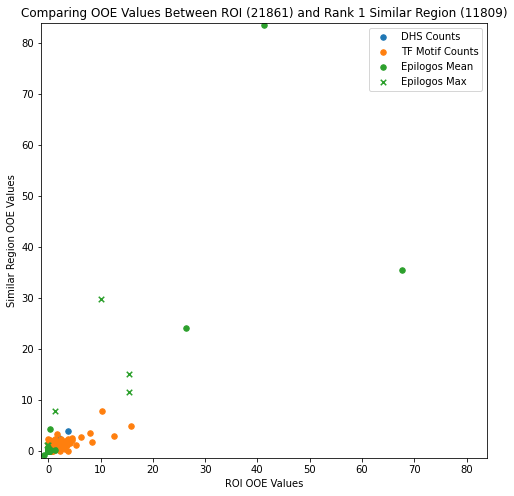

In [31]:
breakdown_score(1)

ROI = 21861
#100 in ROIurl

DHS Cosine Similarity = 0.334
TF Cosine Similarity = 0.5991
Epilogos Cosine Similarity = 0.224

1000th DHS Cosine Similarity for ROI = 0.7772
1000th TF Cosine Similarity for ROI = 0.8231
1000th Epilogos Cosine Similarity for ROI = 0.7487

DHS Scaled Score = 0.0
TF Scaled Score = 0.0
Epilogos Scaled Score = 0.0

Total Score = 0.0

Comparing OOE Values Between ROI (21861) and Rank 99 Similar Region (68289)


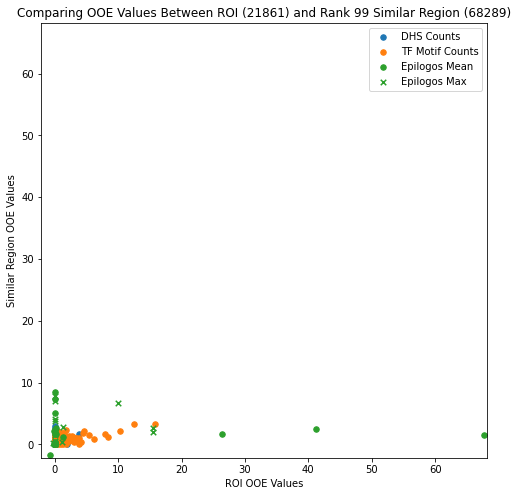

In [32]:
breakdown_score(99)

**OOE rank of each component across all regions**

In [33]:
rank_for_DHS_comps = rankdata(-DHS_ooe, method='average', axis=1)
rank_for_TF_comps = rankdata(-TF_ooe, method='average', axis=1)
rank_for_epilogos_mean_comps = rankdata(-epilogos_ooe[:, :18], method='average', axis=1)
rank_for_epilogos_max_comps = rankdata(-epilogos_ooe[:, 18:], method='average', axis=1)

Text(0.5, 1.0, 'TF Component Ranking Distribution\nAcross Regions (First 15 Components)')

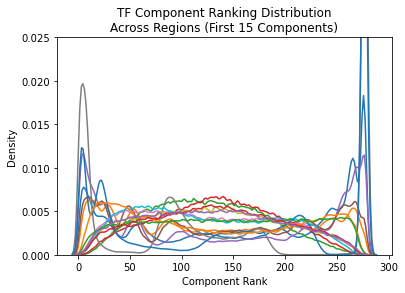

In [25]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_TF_comps[0, :15])):
    sns.kdeplot(rank_for_TF_comps[:, i], bw_adjust=0.2)
# plt.yscale('symlog')
plt.ylim([0, 0.025])
plt.xlabel('Component Rank')
plt.title('TF Component Ranking Distribution\nAcross Regions (First 15 Components)')

Text(0.5, 1.0, 'DHS Component Ranking Distribution Across Regions')

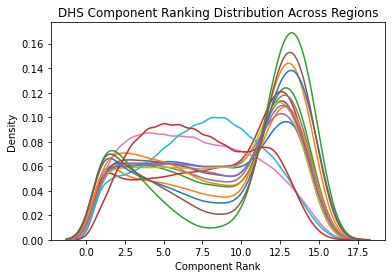

In [26]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_DHS_comps[0, :])):
    sns.kdeplot(rank_for_DHS_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('DHS Component Ranking Distribution Across Regions')

Text(0.5, 1.0, 'Epilogos (Mean) Component Ranking Distribution Across Regions')

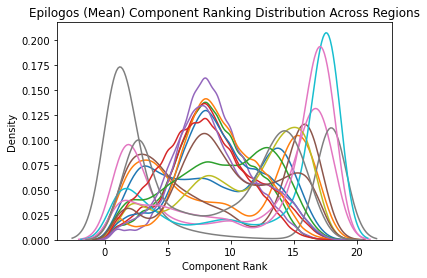

In [27]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_epilogos_mean_comps[0, :])):
    sns.kdeplot(rank_for_epilogos_mean_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('Epilogos (Mean) Component Ranking Distribution Across Regions')

Text(0.5, 1.0, 'Epilogos (Max) Component Ranking Distribution Across Regions')

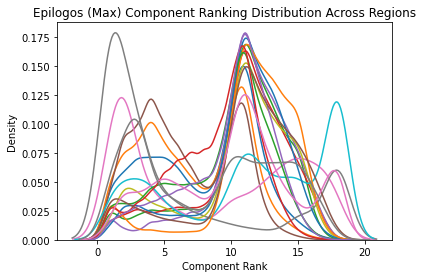

In [28]:
fig = plt.figure()
fig.patch.set_facecolor('white')
for i in range(len(rank_for_epilogos_max_comps[0, :])):
    sns.kdeplot(rank_for_epilogos_max_comps[:, i], bw_adjust=1.5)
plt.xlabel('Component Rank')
plt.title('Epilogos (Max) Component Ranking Distribution Across Regions')

**Generative Model for Epilogos Scores**

In [18]:
# epilogos_ooe_hdf5 = h5py.File('/home/ctrader/region_similarity/data/regions_25kb_CT20220623.epilogosoee.hdf5', 'r')
# epilogos_ooe_arr = epilogos_ooe_hdf5['ooe_arr'][:]
# epilogos_ooe_hdf5.close()

In [35]:
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosmapped.bed', 'r')
epilogos_component_order = np.array(f.readline().strip().split('\t'))[3:]
f.close()

In [38]:
#load score data
epilogos_score_data = []
f = open('/home/ctrader/region_similarity/data/regions_25kb_CT20220708.epilogosmapped.bed', 'r')

next(f)
for line in f:
    epilogos_score_data.append(re.split('\t|\|', line.strip()))
f.close()
epilogos_score_data = np.array(epilogos_score_data)

epilogos_score_data_mean_vals = epilogos_score_data[:, 3::2].astype(float)
epilogos_score_data_max_vals = epilogos_score_data[:, 4::2].astype(float)

In [39]:
top_epilogos_max_comp = np.argmax(epilogos_score_data_max_vals, axis=1)
top_epilogos_mean_comp = np.argmax(epilogos_score_data_mean_vals, axis=1)

In [40]:
epilogos_component_order
epilogos_mapped_color_order = np.array(['#ffc34d', '#ffc34d', '#bdb76b', '#c2e105', '#c2e105', '#ffff00', '#8a91d0', 
                                        '#ffffff', '#808080', '#c0c0c0', '#ff0000', '#cd5c5c', '#ff4500', '#ff4500', 
                                        '#ff4500', '#008000', '#006400', '#66cdaa'])


Top Epilogos Factor for Each 25kb Region


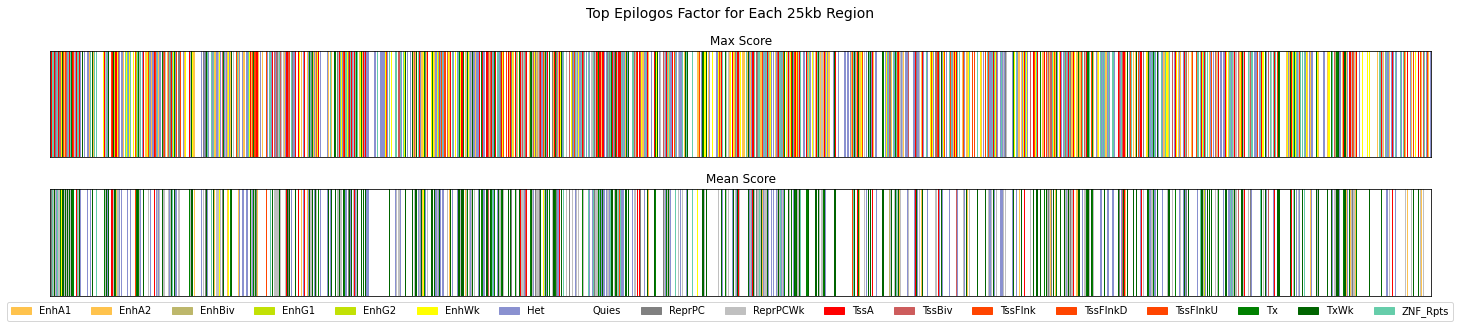

In [72]:
fig, axes = plt.subplots(nrows=2, figsize=(20,4))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes[0].bar(np.arange(len(top_epilogos_max_comp)), 1, color=epilogos_mapped_color_order[top_epilogos_max_comp], width=1)
axes[1].bar(np.arange(len(top_epilogos_mean_comp)), 1, color=epilogos_mapped_color_order[top_epilogos_mean_comp], width=1)

axes[0].set_xlim([0, len(top_epilogos_max_comp)])
axes[0].set_ylim([0, 1])
axes[1].set_xlim([0, len(top_epilogos_mean_comp)])
axes[1].set_ylim([0, 1])


axes[0].set_xticks([])
axes[0].set_yticks([])
axes[1].set_xticks([])
axes[1].set_yticks([])

axes[0].set_title('Max Score')
axes[1].set_title('Mean Score')


handles = []
for c, f in zip(epilogos_mapped_color_order, epilogos_component_order):
    handles.append(mpatches.Patch(color=c, label=f))

fig.legend(handles=handles, loc='lower center', ncol=18)

title = 'Top Epilogos Factor for Each 25kb Region'
fig.suptitle(title, y=1.1, fontsize=14)
print(title)

In [41]:
#counting intersection of epilogos max and mean factors
top_epilogos_comp_max_mean_counts = np.zeros((18, 18), dtype=int)
for i, j in zip(top_epilogos_mean_comp, top_epilogos_max_comp):
    top_epilogos_comp_max_mean_counts[i, j] += 1

Text(0.5, 1.0, 'Chromatin State Top Factors for All 25kb Regions')

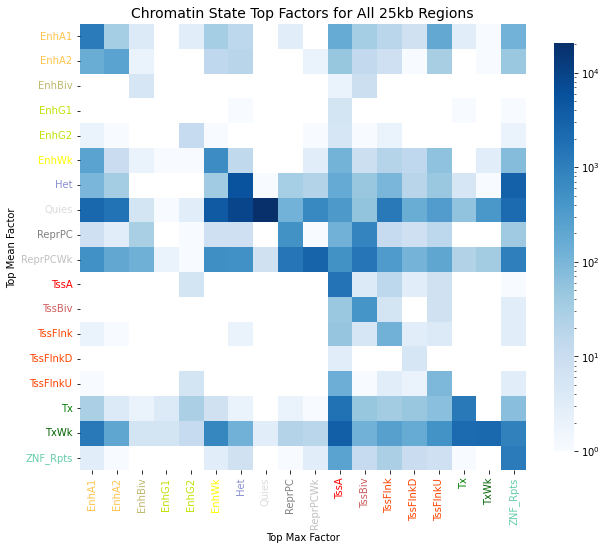

In [42]:
fig, axes = plt.subplots(figsize=(10,10))
fig.patch.set_facecolor('white')

sns.heatmap(top_epilogos_comp_max_mean_counts, cmap='Blues', square=True, norm=LogNorm(), cbar_kws={"shrink": .75})

axes.set_xticklabels(epilogos_component_order, rotation=90)
axes.set_yticklabels(epilogos_component_order, rotation=0)

colors_for_heatmap = epilogos_mapped_color_order
colors_for_heatmap[7]='#dbdbdb'
for (color, xlabel, ylabel) in zip(epilogos_mapped_color_order, axes.xaxis.get_ticklabels(), axes.yaxis.get_ticklabels()):
    xlabel.set_color(color)
    ylabel.set_color(color)

title='Chromatin State Top Factors for All 25kb Regions'

plt.ylabel('Top Mean Factor')
plt.xlabel('Top Max Factor')
plt.title(title, fontsize=14)

In [69]:
# up = np.arange(0, top_max_factor_val, top_max_factor_val/(25000/200/2))
# down = np.arange(top_max_factor_val, 0, -top_max_factor_val/(25000/200/2))[:-1]
# max_path = np.append(up, down)
# max_path

# fig = plt.figure(figsize=(10,6))
# fig.patch.set_facecolor('white')

# top_mean_factor = np.argmax(epilogos_score_data_mean_vals[roi])
# noise = [0]
# for i in range(1, int(25000/200)):
#     noise.append(noise[i-1]+random.gauss(0, 0.1))
# noise = np.array(noise)
# mean_cartoon = np.array([epilogos_score_data_mean_vals[roi, top_mean_factor]]*int(25000/200)) + noise

# top_max_factor = np.argmax(epilogos_score_data_max_vals[roi])
# top_max_factor_val = epilogos_score_data_max_vals[roi, top_max_factor]

# up = np.arange(0, top_max_factor_val, top_max_factor_val/(25000/200/2))
# down = np.arange(top_max_factor_val, 0, -top_max_factor_val/(25000/200/2))[:-1]


# max_cartoon = np.append(up, down)

# plt.fill_between(np.arange(0, 25000, 200), mean_cartoon, color=epilogos_mapped_color_order[top_mean_factor])
# plt.fill_between(np.arange(0, 25000, 200), max_cartoon, color=epilogos_mapped_color_order[top_max_factor])

Text(0.51, 0.98, 'Summerized Chromatin State Pattern for ROI 21861')

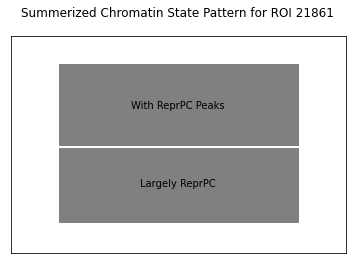

In [43]:
fig, axes = plt.subplots(figsize=(6,4))
fig.patch.set_facecolor('white')

top_mean_factor = np.argmax(epilogos_score_data_mean_vals[roi])
top_max_factor = np.argmax(epilogos_score_data_max_vals[roi])


mean_patch = mpatches.Rectangle((0, 0), 1, 0.48, angle=0.0, color=epilogos_mapped_color_order[top_mean_factor])
axes.add_patch(mean_patch)
axes.text(0.5, 0.25, 'Largely %s' %(epilogos_component_order[top_mean_factor]), ha='center', va='center')

max_patch = mpatches.Rectangle((0, 0.5), 1, 0.52, angle=0.0, color=epilogos_mapped_color_order[top_max_factor])
axes.add_patch(max_patch)
axes.text(0.5, 0.75, 'With %s Peaks' %(epilogos_component_order[top_max_factor]), ha='center', va='center')

axes.set_xlim([-0.2, 1.2])
axes.set_ylim([-0.2, 1.2])

axes.set_xticks([])
axes.set_yticks([])

fig.suptitle('Summerized Chromatin State Pattern for ROI %s' %(roi), x=0.51)

**Finding Most Interesting Region**

In [13]:
# epilogos_scaled_vals_full
# epilogos_similar_regions_full
# TF_scaled_vals_full
# TF_similar_regions_full
# DHS_scaled_vals_full
# DHS_similar_regions_full

In [433]:
regions_scores = []
DHS_individual_scores = []
TF_individual_scores = []
epilogos_individual_scores = []
for i in range(len(DHS_similar_regions_full)):
    DHS_arr_i = np.zeros(len(DHS_similar_regions_full))
    TF_arr_i = np.zeros(len(TF_similar_regions_full))
    epilogos_arr_i = np.zeros(len(epilogos_similar_regions_full))

    DHS_arr_i[DHS_similar_regions_full[i]] = DHS_scaled_vals_full[i]
    TF_arr_i[TF_similar_regions_full[i]] = TF_scaled_vals_full[i]
    epilogos_arr_i[epilogos_similar_regions_full[i]] = epilogos_scaled_vals_full[i]
    
    score_arr_i = 1 - ((1 - epilogos_arr_i) * (1 - DHS_arr_i) * (1 - TF_arr_i))
    top_100_inds = np.argsort(-score_arr_i)[:100]
    
    regions_scores.append(score_arr_i[top_100_inds])
    DHS_individual_scores.append(DHS_arr_i[top_100_inds])
    TF_individual_scores.append(TF_arr_i[top_100_inds])
    epilogos_individual_scores.append(epilogos_arr_i[top_100_inds])
    
regions_scores = np.array(regions_scores)
DHS_individual_scores = np.array(DHS_individual_scores)
TF_individual_scores = np.array(TF_individual_scores)
epilogos_individual_scores = np.array(epilogos_individual_scores)

In [434]:
average_of_scores = np.mean([np.mean(DHS_individual_scores, axis=1), 
                             np.mean(TF_individual_scores, axis=1), 
                             np.mean(epilogos_individual_scores, axis=1),
                             np.mean(regions_scores, axis=1)], 
                            axis=0)

In [435]:
np.argsort(-average_of_scores)[20000]

67717